In [22]:
# ==================================================================================
# ЗАГРУЗКА ДАННЫХ И ИНИЦИАЛИЗАЦИЯ
# ==================================================================================
import pandas as pd
import numpy as np
from tabulate import tabulate
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем данные
df = pd.read_csv('test.csv', decimal=',')

print("📊 ДАННЫЕ ЗАГРУЖЕНЫ")
print("=" * 30)
print(f"Количество спектаклей: {len(df)}")
print(f"Колонки: {list(df.columns)}")
print("\n🎭 ПЕРВЫЕ 5 СПЕКТАКЛЕЙ:")
print(tabulate(df.head()[['ID', 'Название постановки', 'Жанр', 'Рейтинг', 'Театр']], 
               headers='keys', tablefmt='grid'))

print("\n✅ Все библиотеки импортированы!")
print("🚀 Система готова к работе!")

print("\n✅ Система готова к работе!")
print("🚀 Запустите: improved_interactive_system()")


📊 ДАННЫЕ ЗАГРУЖЕНЫ
Количество спектаклей: 30
Колонки: ['ID', 'Название постановки', 'Длительность (мин)', 'Год постановки', 'Количество антрактов', 'Жанр', 'Язык исполнения', 'Целевая аудитория', 'Стиль', 'Проводится на открытом воздухе?', 'Семейный?', 'Для детей?', 'Платный?', 'Теги', 'Темы', 'Режиссер', 'Театр', 'Рейтинг', 'Награды', 'Логика']

🎭 ПЕРВЫЕ 5 СПЕКТАКЛЕЙ:
+----+------+-----------------------+----------+-----------+------------------------------------------------------------------------+
|    |   ID | Название постановки   | Жанр     |   Рейтинг | Театр                                                                  |
+====+======+=======================+==========+===========+========================================================================+
|  0 |    1 | Вишневый сад          | Комедия  |       7.8 | Театр им. Пушкина                                                      |
+----+------+-----------------------+----------+-----------+--------------------------------

In [26]:
# ==================================================================================
# ЛАБОРАТОРНАЯ РАБОТА 2: ТЕПЛОВЫЕ КАРТЫ РАССТОЯНИЙ
# ==================================================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances
from sklearn.preprocessing import StandardScaler
import numpy as np

class DistanceAnalysisSystem:
    """Система анализа расстояний между спектаклями с тепловыми картами"""
    
    def __init__(self, df):
        self.df = df.copy()
        self.prepared_data = None
        self.distance_matrices = {}
        
    def prepare_data(self):
        """Подготавливает данные для анализа расстояний с нормализацией от 0 до 1"""
        print("🔧 ПОДГОТОВКА ДАННЫХ ДЛЯ АНАЛИЗА РАССТОЯНИЙ")
        print("=" * 60)
        
        # Выбираем ВСЕ признаки для анализа (кроме ID)
        all_columns = self.df.columns.tolist()
        features = [col for col in all_columns if col != 'ID']
        
        print(f"📊 ВСЕ ПРИЗНАКИ ДЛЯ АНАЛИЗА ({len(features)}):")
        for i, feature in enumerate(features, 1):
            print(f"   {i}. {feature}")
        
        # Создаем копию данных
        self.prepared_data = self.df[features].copy()
        
        # Обрабатываем числовые признаки
        numeric_features = []
        categorical_features = []
        
        for col in features:
            if self.prepared_data[col].dtype in ['int64', 'float64']:
                numeric_features.append(col)
            else:
                # Пытаемся преобразовать в числовой формат
                try:
                    if col == 'Рейтинг':
                        # Специальная обработка для рейтинга
                        self.prepared_data[col] = pd.to_numeric(
                            self.prepared_data[col].astype(str).str.replace(',', '.'), 
                            errors='coerce'
                        )
                        numeric_features.append(col)
                    else:
                        # Пытаемся преобразовать другие колонки
                        converted = pd.to_numeric(self.prepared_data[col], errors='coerce')
                        if not converted.isnull().all():
                            self.prepared_data[col] = converted
                            numeric_features.append(col)
                        else:
                            categorical_features.append(col)
                except:
                    categorical_features.append(col)
        
        print(f"\n🔢 ЧИСЛОВЫЕ ПРИЗНАКИ ({len(numeric_features)}): {numeric_features}")
        print(f"📝 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ ({len(categorical_features)}): {categorical_features}")
        
        # Кодируем категориальные признаки
        self.label_encoders = {}
        for col in categorical_features:
            le = LabelEncoder()
            self.prepared_data[f'{col}_encoded'] = le.fit_transform(self.prepared_data[col].astype(str))
            self.label_encoders[col] = le
            print(f"✅ Закодирован категориальный признак: {col}")
        
        # Заполняем пропуски в числовых признаках
        for col in numeric_features:
            if self.prepared_data[col].isnull().any():
                mean_val = self.prepared_data[col].mean()
                self.prepared_data[col] = self.prepared_data[col].fillna(mean_val)
                print(f"✅ Заполнены пропуски в '{col}' средним значением: {mean_val:.2f}")
        
        # Выбираем все признаки для нормализации (числовые + закодированные)
        all_features_for_scaling = numeric_features + [f'{col}_encoded' for col in categorical_features]
        
        print(f"\n📊 ПРИЗНАКИ ДЛЯ НОРМАЛИЗАЦИИ ({len(all_features_for_scaling)}):")
        for i, feature in enumerate(all_features_for_scaling, 1):
            print(f"   {i}. {feature}")
        
        # Нормализуем данные от 0 до 1 (Min-Max нормализация)
        from sklearn.preprocessing import MinMaxScaler
        scaler = MinMaxScaler()
        self.prepared_data_scaled = scaler.fit_transform(self.prepared_data[all_features_for_scaling])
        
        # Сохраняем информацию о признаках
        self.numeric_features = numeric_features
        self.categorical_features = categorical_features
        self.all_features_for_scaling = all_features_for_scaling
        
        print(f"\n✅ Данные подготовлены: {self.prepared_data.shape}")
        print(f"✅ Нормализация от 0 до 1 выполнена для {len(all_features_for_scaling)} признаков")
        print(f"📊 Диапазон значений после нормализации: [{self.prepared_data_scaled.min():.3f}, {self.prepared_data_scaled.max():.3f}]")
        
        return self.prepared_data_scaled
    
    def calculate_distances(self):
        """Вычисляет различные типы расстояний"""
        print("\n📊 ВЫЧИСЛЕНИЕ РАССТОЯНИЙ")
        print("=" * 40)
        
        if self.prepared_data_scaled is None:
            print("❌ Сначала подготовьте данные!")
            return
        
        # Евклидово расстояние
        print("1. Вычисляем Евклидово расстояние...")
        euclidean_dist = euclidean_distances(self.prepared_data_scaled)
        self.distance_matrices['euclidean'] = euclidean_dist
        print(f"   ✅ Евклидово расстояние: {euclidean_dist.shape}")
        
        # Расстояние Манхэттена
        print("2. Вычисляем расстояние Манхэттена...")
        manhattan_dist = manhattan_distances(self.prepared_data_scaled)
        self.distance_matrices['manhattan'] = manhattan_dist
        print(f"   ✅ Расстояние Манхэттена: {manhattan_dist.shape}")
        
        # Косинусное расстояние
        print("3. Вычисляем косинусное расстояние...")
        cosine_dist = cosine_distances(self.prepared_data_scaled)
        self.distance_matrices['cosine'] = cosine_dist
        print(f"   ✅ Косинусное расстояние: {cosine_dist.shape}")
        
        print("\n✅ Все расстояния вычислены!")
    
    def create_heatmaps(self):
        """Создает тепловые карты для всех типов расстояний (каждая отдельно)"""
        print("\n🔥 СОЗДАНИЕ ТЕПЛОВЫХ КАРТ")
        print("=" * 50)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Нормализуем каждую матрицу расстояний от 0 до 1 для лучшего сравнения
        print("📊 Вычисляем общие границы для всех метрик...")
        all_values = []
        for dist_type, matrix in self.distance_matrices.items():
            all_values.extend(matrix.flatten())
        
        global_min = min(all_values)
        global_max = max(all_values)
        
        print(f"🌍 Глобальные границы: [{global_min:.4f}, {global_max:.4f}]")
        
        # Нормализуем все матрицы к ОДНОМУ диапазону
        normalized_matrices = {}

        for dist_type, matrix in self.distance_matrices.items():
            # Нормализуем каждую матрицу к своему диапазону [0,1]
            matrix_min = matrix.min()
            matrix_max = matrix.max()
            
            if matrix_max != matrix_min:
                normalized_matrices[dist_type] = (matrix - matrix_min) / (matrix_max - matrix_min)
            else:
                normalized_matrices[dist_type] = matrix
            
            print(f"✅ {dist_type}: [{matrix_min:.4f}, {matrix_max:.4f}] → [0.0000, 1.0000]")
        
        # 1. Евклидово расстояние
        print("\n📊 ТЕПЛОВАЯ КАРТА 1: ЕВКЛИДОВО РАССТОЯНИЕ")
        plt.figure(figsize=(12, 10))
        sns.heatmap(
            normalized_matrices['euclidean'], 
            cmap='YlOrRd', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            fmt='.3f'
        )
        
        # Добавляем информацию о признаках в заголовок
        features_info = f"Признаки: {len(self.all_features_for_scaling)} (числовые: {len(self.numeric_features)}, категориальные: {len(self.categorical_features)})"
        plt.title(f'ЕВКЛИДОВО РАССТОЯНИЕ\n(Нормализовано от 0 до 1)\n{features_info}', 
                 fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=12)
        plt.ylabel('Спектакль ID', fontsize=12)
        plt.tight_layout()
        plt.show()
        
        # 2. Расстояние Манхэттена
        print("\n📊 ТЕПЛОВАЯ КАРТА 2: РАССТОЯНИЕ МАНХЭТТЕНА")
        plt.figure(figsize=(12, 10))
        sns.heatmap(
            normalized_matrices['manhattan'], 
            cmap='Blues', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            fmt='.3f'
        )
        plt.title(f'РАССТОЯНИЕ МАНХЭТТЕНА\n(Нормализовано от 0 до 1)\n{features_info}', 
                 fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=12)
        plt.ylabel('Спектакль ID', fontsize=12)
        plt.tight_layout()
        plt.show()
        
        # 3. Косинусное расстояние
        print("\n📊 ТЕПЛОВАЯ КАРТА 3: КОСИНУСНОЕ РАССТОЯНИЕ")
        plt.figure(figsize=(12, 10))
        sns.heatmap(
            normalized_matrices['cosine'], 
            cmap='Greens', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            fmt='.3f'
        )
        plt.title(f'КОСИНУСНОЕ РАССТОЯНИЕ\n(Нормализовано от 0 до 1)\n{features_info}', 
                 fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=12)
        plt.ylabel('Спектакль ID', fontsize=12)
        plt.tight_layout()
        plt.show()
        
        # Сохраняем нормализованные матрицы для анализа
        self.normalized_matrices = normalized_matrices
        
        print("\n✅ Все тепловые карты созданы отдельно!")
        print("📊 Каждая карта нормализована от 0 до 1 для лучшего сравнения")
    
    def analyze_distances(self):
        """Анализирует и сравнивает различные типы расстояний"""
        print("\n📈 АНАЛИЗ РАССТОЯНИЙ")
        print("=" * 40)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Статистика по каждому типу расстояний (оригинальные значения)
        print("🔍 СТАТИСТИКА ОРИГИНАЛЬНЫХ РАССТОЯНИЙ:")
        for dist_type, matrix in self.distance_matrices.items():
            print(f"\n{dist_type.upper()}:")
            print(f"   Минимальное расстояние: {matrix.min():.4f}")
            print(f"   Максимальное расстояние: {matrix.max():.4f}")
            print(f"   Среднее расстояние: {matrix.mean():.4f}")
            print(f"   Медианное расстояние: {np.median(matrix):.4f}")
            print(f"   Стандартное отклонение: {matrix.std():.4f}")
        
        # Статистика по нормализованным расстояниям
        if hasattr(self, 'normalized_matrices'):
            print("\n🔍 СТАТИСТИКА НОРМАЛИЗОВАННЫХ РАССТОЯНИЙ (0-1):")
            for dist_type, matrix in self.normalized_matrices.items():
                print(f"\n{dist_type.upper()} (нормализованное):")
                print(f"   Минимальное расстояние: {matrix.min():.4f}")
                print(f"   Максимальное расстояние: {matrix.max():.4f}")
                print(f"   Среднее расстояние: {matrix.mean():.4f}")
                print(f"   Медианное расстояние: {np.median(matrix):.4f}")
                print(f"   Стандартное отклонение: {matrix.std():.4f}")
        
        # Сравнение расстояний (оригинальные)
        print(f"\n📊 КОРРЕЛЯЦИЯ МЕЖДУ РАССТОЯНИЯМИ:")
        print(f"   Евклидово vs Манхэттен: {np.corrcoef(self.distance_matrices['euclidean'].flatten(), self.distance_matrices['manhattan'].flatten())[0,1]:.4f}")
        print(f"   Евклидово vs Косинусное: {np.corrcoef(self.distance_matrices['euclidean'].flatten(), self.distance_matrices['cosine'].flatten())[0,1]:.4f}")
        print(f"   Манхэттен vs Косинусное: {np.corrcoef(self.distance_matrices['manhattan'].flatten(), self.distance_matrices['cosine'].flatten())[0,1]:.4f}")
        
        # Сравнение нормализованных расстояний
        if hasattr(self, 'normalized_matrices'):
            print(f"\n📊 КОРРЕЛЯЦИЯ НОРМАЛИЗОВАННЫХ РАССТОЯНИЙ:")
            print(f"   Евклидово vs Манхэттен: {np.corrcoef(self.normalized_matrices['euclidean'].flatten(), self.normalized_matrices['manhattan'].flatten())[0,1]:.4f}")
            print(f"   Евклидово vs Косинусное: {np.corrcoef(self.normalized_matrices['euclidean'].flatten(), self.normalized_matrices['cosine'].flatten())[0,1]:.4f}")
            print(f"   Манхэттен vs Косинусное: {np.corrcoef(self.normalized_matrices['manhattan'].flatten(), self.normalized_matrices['cosine'].flatten())[0,1]:.4f}")
    
    def find_best_distance(self):
        """Определяет лучший тип расстояния для анализа"""
        print("\n🏆 ОПРЕДЕЛЕНИЕ ЛУЧШЕГО РАССТОЯНИЯ")
        print("=" * 50)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Используем нормализованные данные для сравнения, если они есть
        matrices_to_analyze = self.normalized_matrices if hasattr(self, 'normalized_matrices') else self.distance_matrices
        matrix_type = "нормализованных" if hasattr(self, 'normalized_matrices') else "оригинальных"
        
        print(f"📊 Анализ на основе {matrix_type} данных:")
        
        # Критерии для выбора лучшего расстояния
        criteria = {}
        
        for dist_type, matrix in matrices_to_analyze.items():
            # 1. Разброс значений (чем больше, тем лучше для дифференциации)
            spread = matrix.max() - matrix.min()
            
            # 2. Стандартное отклонение (показывает вариативность)
            std_dev = matrix.std()
            
            # 3. Количество уникальных значений (чем больше, тем лучше)
            unique_values = len(np.unique(matrix))
            
            # 4. Коэффициент вариации (относительная вариативность)
            cv = std_dev / matrix.mean() if matrix.mean() != 0 else 0
            
            # 5. Информационная энтропия (показывает разнообразие)
            hist, _ = np.histogram(matrix.flatten(), bins=50)
            hist = hist[hist > 0]  # Убираем нулевые значения
            prob = hist / hist.sum()
            entropy = -np.sum(prob * np.log2(prob))
            
            criteria[dist_type] = {
                'spread': spread,
                'std_dev': std_dev,
                'unique_values': unique_values,
                'cv': cv,
                'entropy': entropy
            }
        
        # Выводим критерии
        print("📊 КРИТЕРИИ ОЦЕНКИ:")
        for dist_type, crit in criteria.items():
            print(f"\n{dist_type.upper()}:")
            print(f"   Разброс: {crit['spread']:.4f}")
            print(f"   Стандартное отклонение: {crit['std_dev']:.4f}")
            print(f"   Уникальных значений: {crit['unique_values']}")
            print(f"   Коэффициент вариации: {crit['cv']:.4f}")
            print(f"   Информационная энтропия: {crit['entropy']:.4f}")
        
        # Определяем лучший тип расстояния с улучшенными весами
        best_distance = max(criteria.keys(), key=lambda x: (
            criteria[x]['spread'] * 0.25 +      # 25% за разброс
            criteria[x]['std_dev'] * 0.25 +     # 25% за стандартное отклонение
            criteria[x]['unique_values'] * 0.15 + # 15% за уникальность
            criteria[x]['cv'] * 0.15 +          # 15% за коэффициент вариации
            criteria[x]['entropy'] * 0.20       # 20% за информационную энтропию
        ))
        
        print(f"\n🏆 ЛУЧШЕЕ РАССТОЯНИЕ: {best_distance.upper()}")
        print(f"   Обоснование: наилучший баланс разброса, вариативности, уникальности и информационной энтропии")
        print(f"   Анализ проведен на основе {matrix_type} данных (0-1)")
        
        return best_distance
    
    def create_comparison_table(self):
        """Создает сравнительную таблицу всех типов расстояний"""
        print("\n📋 СРАВНИТЕЛЬНАЯ ТАБЛИЦА РАССТОЯНИЙ")
        print("=" * 60)
        
        if not hasattr(self, 'normalized_matrices'):
            print("❌ Сначала создайте тепловые карты!")
            return
        
        # Создаем сравнительную таблицу
        comparison_data = []
        
        for dist_type, matrix in self.normalized_matrices.items():
            comparison_data.append({
                'Тип расстояния': dist_type.upper(),
                'Мин. значение': f"{matrix.min():.4f}",
                'Макс. значение': f"{matrix.max():.4f}",
                'Среднее': f"{matrix.mean():.4f}",
                'Стд. отклонение': f"{matrix.std():.4f}",
                'Уникальных значений': len(np.unique(matrix)),
                'Разброс': f"{matrix.max() - matrix.min():.4f}"
            })
        
        # Выводим таблицу
        comparison_df = pd.DataFrame(comparison_data)
        print(tabulate(comparison_df, headers='keys', tablefmt='grid', stralign='center'))
        
        return comparison_df
    
    def show_features_info(self):
        """Показывает детальную информацию о всех признаках"""
        print("\n📋 ДЕТАЛЬНАЯ ИНФОРМАЦИЯ О ПРИЗНАКАХ")
        print("=" * 60)
        
        if not hasattr(self, 'all_features_for_scaling'):
            print("❌ Сначала подготовьте данные!")
            return
        
        print(f"🔢 ЧИСЛОВЫЕ ПРИЗНАКИ ({len(self.numeric_features)}):")
        for i, feature in enumerate(self.numeric_features, 1):
            min_val = self.prepared_data[feature].min()
            max_val = self.prepared_data[feature].max()
            mean_val = self.prepared_data[feature].mean()
            print(f"   {i}. {feature}: [{min_val:.2f}, {max_val:.2f}], среднее: {mean_val:.2f}")
        
        print(f"\n📝 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ ({len(self.categorical_features)}):")
        for i, feature in enumerate(self.categorical_features, 1):
            unique_values = self.prepared_data[feature].nunique()
            print(f"   {i}. {feature}: {unique_values} уникальных значений")
            # Показываем первые несколько значений
            sample_values = self.prepared_data[feature].unique()[:5]
            print(f"      Примеры: {', '.join(map(str, sample_values))}")
            if len(self.prepared_data[feature].unique()) > 5:
                print(f"      ... и еще {len(self.prepared_data[feature].unique()) - 5}")
        
        print(f"\n📊 ВСЕГО ПРИЗНАКОВ ДЛЯ АНАЛИЗА: {len(self.all_features_for_scaling)}")
        print(f"   - Числовые: {len(self.numeric_features)}")
        print(f"   - Категориальные (закодированные): {len(self.categorical_features)}")
        print(f"   - Всего спектаклей: {len(self.prepared_data)}")
    
    def run_full_analysis(self):
        """Запускает полный анализ расстояний"""
        print("🚀 ПОЛНЫЙ АНАЛИЗ РАССТОЯНИЙ")
        print("=" * 60)
        
        # 1. Подготовка данных
        self.prepare_data()
        
        # 2. Показ информации о признаках
        self.show_features_info()
        
        # 3. Вычисление расстояний
        self.calculate_distances()
        
        # 4. Создание тепловых карт (каждая отдельно)
        self.create_heatmaps()
        
        # 5. Создание сравнительной таблицы
        self.create_comparison_table()
        
        # 6. Анализ расстояний
        self.analyze_distances()
        
        # 7. Определение лучшего расстояния
        best_distance = self.find_best_distance()
        
        print(f"\n✅ АНАЛИЗ ЗАВЕРШЕН!")
        print(f"🏆 Рекомендуемое расстояние: {best_distance.upper()}")
        print(f"📊 Создано 3 отдельные тепловые карты с нормализацией 0-1")
        print(f"📋 Создана сравнительная таблица всех типов расстояний")
        print(f"🔍 Проанализированы ВСЕ признаки: {len(self.all_features_for_scaling)}")
        print(f"   - Числовые: {len(self.numeric_features)}")
        print(f"   - Категориальные: {len(self.categorical_features)}")
        
        return best_distance

print("✅ Система анализа расстояний создана!")
print("🚀 Для запуска: distance_system.run_full_analysis()")


✅ Система анализа расстояний создана!
🚀 Для запуска: distance_system.run_full_analysis()


🚀 ПОЛНЫЙ АНАЛИЗ РАССТОЯНИЙ
🔧 ПОДГОТОВКА ДАННЫХ ДЛЯ АНАЛИЗА РАССТОЯНИЙ
📊 ВСЕ ПРИЗНАКИ ДЛЯ АНАЛИЗА (19):
   1. Название постановки
   2. Длительность (мин)
   3. Год постановки
   4. Количество антрактов
   5. Жанр
   6. Язык исполнения
   7. Целевая аудитория
   8. Стиль
   9. Проводится на открытом воздухе?
   10. Семейный?
   11. Для детей?
   12. Платный?
   13. Теги
   14. Темы
   15. Режиссер
   16. Театр
   17. Рейтинг
   18. Награды
   19. Логика

🔢 ЧИСЛОВЫЕ ПРИЗНАКИ (5): ['Длительность (мин)', 'Год постановки', 'Количество антрактов', 'Рейтинг', 'Логика']
📝 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ (14): ['Название постановки', 'Жанр', 'Язык исполнения', 'Целевая аудитория', 'Стиль', 'Проводится на открытом воздухе?', 'Семейный?', 'Для детей?', 'Платный?', 'Теги', 'Темы', 'Режиссер', 'Театр', 'Награды']
✅ Закодирован категориальный признак: Название постановки
✅ Закодирован категориальный признак: Жанр
✅ Закодирован категориальный признак: Язык исполнения
✅ Закодирован категориальный признак: Цел

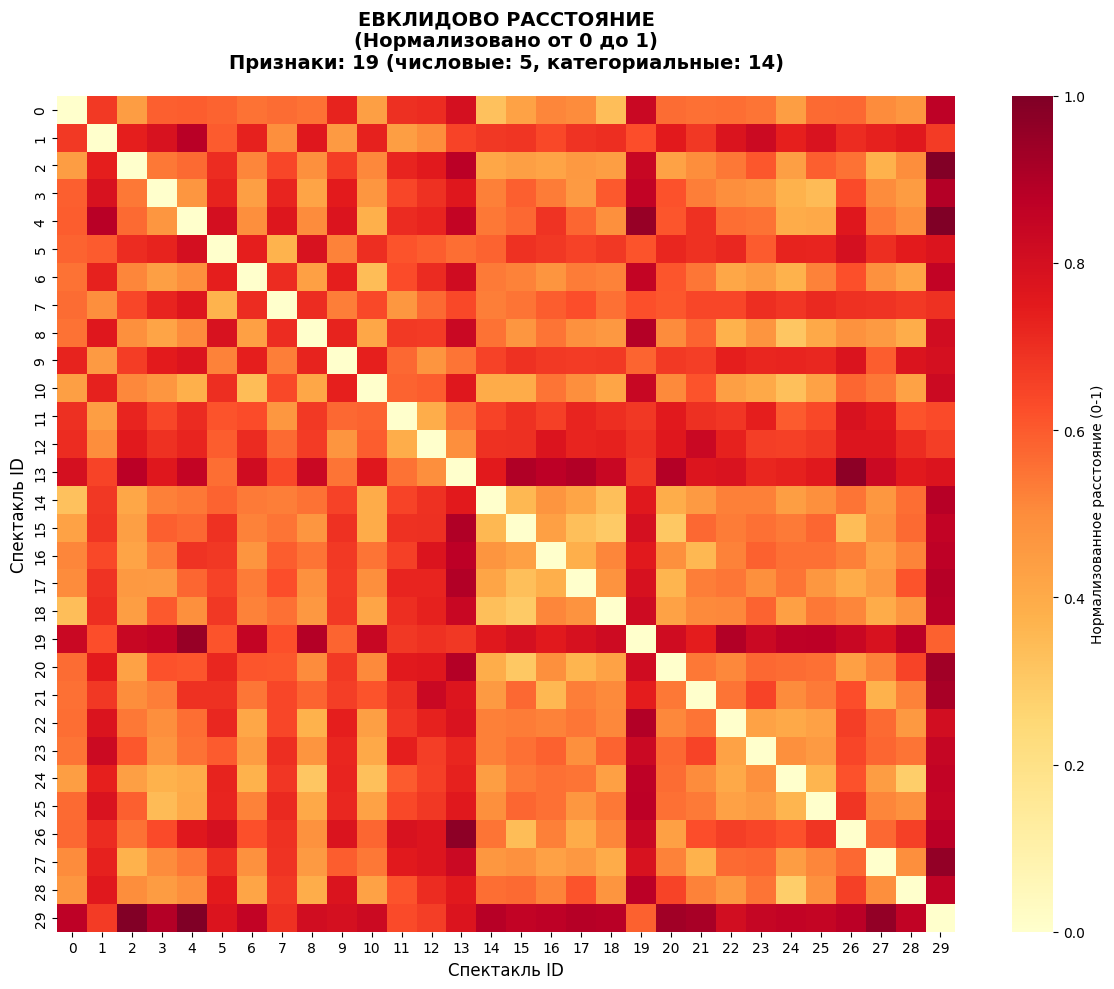


📊 ТЕПЛОВАЯ КАРТА 2: РАССТОЯНИЕ МАНХЭТТЕНА


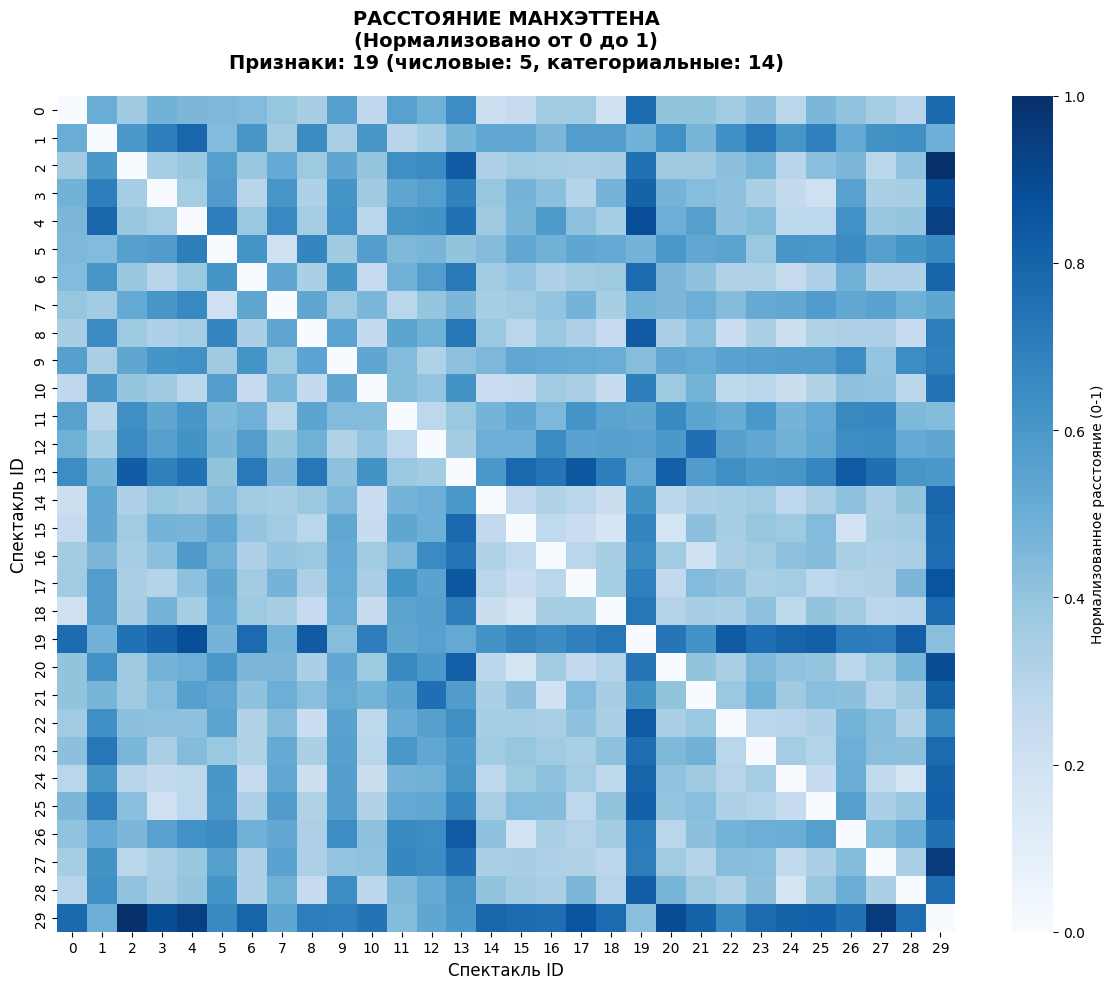


📊 ТЕПЛОВАЯ КАРТА 3: КОСИНУСНОЕ РАССТОЯНИЕ


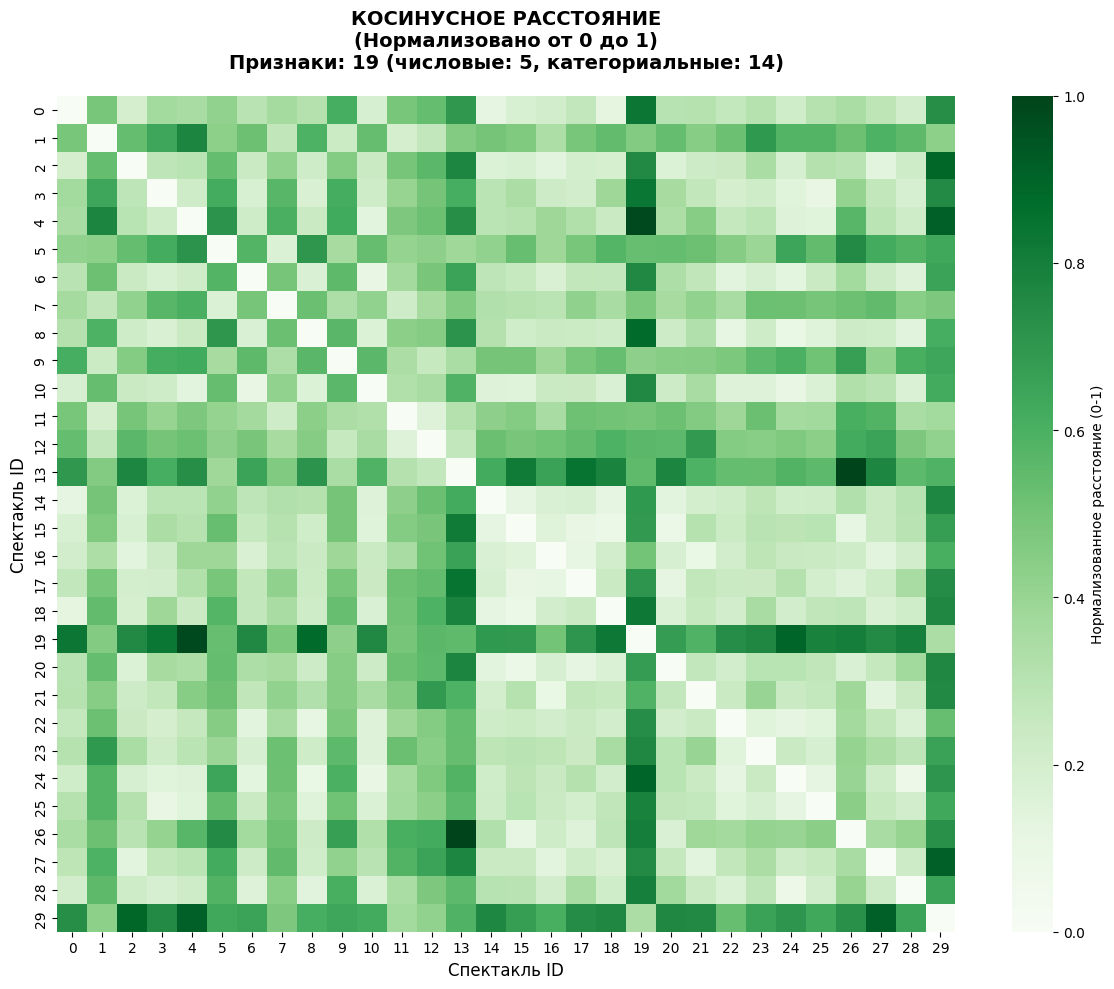


✅ Все тепловые карты созданы отдельно!
📊 Каждая карта нормализована от 0 до 1 для лучшего сравнения

📋 СРАВНИТЕЛЬНАЯ ТАБЛИЦА РАССТОЯНИЙ
+----+------------------+-----------------+------------------+-----------+-------------------+-----------------------+-----------+
|    |  Тип расстояния  |   Мин. значение |   Макс. значение |   Среднее |   Стд. отклонение |   Уникальных значений |   Разброс |
+====+==================+=================+==================+===========+===================+=======================+===========+
|  0 |    EUCLIDEAN     |               0 |                1 |    0.5924 |            0.1845 |                   437 |         1 |
+----+------------------+-----------------+------------------+-----------+-------------------+-----------------------+-----------+
|  1 |    MANHATTAN     |               0 |                1 |    0.4616 |            0.1825 |                   436 |         1 |
+----+------------------+-----------------+------------------+-----------+---

In [27]:
# ==================================================================================
# ЗАПУСК ЛАБОРАТОРНОЙ РАБОТЫ 2 (С ВСЕМИ ПРИЗНАКАМИ)
# ==================================================================================

# Создаем систему анализа расстояний
distance_system = DistanceAnalysisSystem(df)

# Запускаем полный анализ
best_distance = distance_system.run_full_analysis()


In [6]:
# ==================================================================================
# ЛАБОРАТОРНАЯ РАБОТА 3: ИНТЕРАКТИВНАЯ СИСТЕМА РЕКОМЕНДАЦИЙ НА ОСНОВЕ ЕВКЛИДОВА РАССТОЯНИЯ
# ==================================================================================

class InteractiveRecommendationSystem:
    """Интерактивная система рекомендаций на основе Евклидова расстояния"""
    
    def __init__(self, df, distance_matrix):
        self.df = df.copy()
        self.distance_matrix = distance_matrix
        self.likes = []
        self.dislikes = []
        self.ranking = None
        
        print("🚀 ИНТЕРАКТИВНАЯ СИСТЕМА РЕКОМЕНДАЦИЙ")
        print("=" * 60)
        print(f"📊 Загружено {len(df)} спектаклей")
        print(f"📏 Матрица Евклидова расстояния: {distance_matrix.shape}")
        
    def show_spectacles_table(self):
        """Показывает таблицу всех спектаклей"""
        print("\n🎭 ВСЕ СПЕКТАКЛИ:")
        print("-" * 80)
        display_df = self.df[['ID', 'Название постановки', 'Жанр', 'Рейтинг', 'Театр']]
        print(tabulate(display_df, headers='keys', tablefmt='grid', floatfmt='.1f'))
        
    def add_like(self, object_id):
        """Добавляет лайк объекту"""
        if object_id not in self.df['ID'].values:
            print(f"❌ Спектакль с ID {object_id} не найден!")
            available_ids = sorted(self.df['ID'].tolist())
            print(f"💡 Доступные ID: {available_ids}")
            return False
        
        if object_id in self.likes:
            print(f"⚠️ Спектакль ID: {object_id} уже в лайках")
            return False
        
        if object_id in self.dislikes:
            print(f"⚠️ Спектакль ID: {object_id} уже в дизлайках. Сначала удалите дизлайк!")
            return False
        
        self.likes.append(object_id)
        print(f"✅ Добавлен лайк спектаклю ID: {object_id}")
        self._update_ranking()  # Автоматически покажет полную таблицу
        return True
    
    def add_dislike(self, object_id):
        """Добавляет дизлайк объекту"""
        if object_id not in self.df['ID'].values:
            print(f"❌ Спектакль с ID {object_id} не найден!")
            available_ids = sorted(self.df['ID'].tolist())
            print(f"💡 Доступные ID: {available_ids}")
            return False
        
        if object_id in self.dislikes:
            print(f"⚠️ Спектакль ID: {object_id} уже в дизлайках")
            return False
        
        if object_id in self.likes:
            print(f"⚠️ Спектакль ID: {object_id} уже в лайках. Сначала удалите лайк!")
            return False
        
        self.dislikes.append(object_id)
        print(f"❌ Добавлен дизлайк спектаклю ID: {object_id}")
        self._update_ranking()  # Автоматически покажет полную таблицу
        return True
    
    def remove_like(self, object_id):
        """Удаляет лайк"""
        if object_id in self.likes:
            self.likes.remove(object_id)
            print(f"🗑️ Удален лайк спектаклю ID: {object_id}")
            self._update_ranking()  # Автоматически покажет полную таблицу
            return True
        else:
            print(f"⚠️ Спектакль ID: {object_id} не найден в лайках")
            return False
    
    def remove_dislike(self, object_id):
        """Удаляет дизлайк"""
        if object_id in self.dislikes:
            self.dislikes.remove(object_id)
            print(f"🗑️ Удален дизлайк спектаклю ID: {object_id}")
            self._update_ranking()  # Автоматически покажет полную таблицу
            return True
        else:
            print(f"⚠️ Спектакль ID: {object_id} не найден в дизлайках")
            return False
    
    def _update_ranking(self):
        """Обновляет рейтинг на основе лайков и дизлайков"""
        if not self.likes and not self.dislikes:
            print("⚠️ Нет лайков или дизлайков для создания рейтинга")
            self.ranking = None
            return
        
        print("🔄 Обновление рейтинга на основе Евклидова расстояния...")
        
        # Создаем копию данных
        ranking_df = self.df.copy()
        
        # Инициализируем оценки схожести
        similarity_scores = np.zeros(len(self.df))
        
        # Обрабатываем лайки (увеличивают схожесть)
        if self.likes:
            for like_id in self.likes:
                like_idx = self.df[self.df['ID'] == like_id].index[0]
                
                # Используем Евклидово расстояние для вычисления схожести
                # Чем меньше расстояние, тем больше схожесть
                distances = self.distance_matrix[like_idx]
                # Преобразуем расстояние в схожесть (инвертируем)
                similarities = 1 / (1 + distances)  # Добавляем 1 чтобы избежать деления на 0
                similarity_scores += similarities
            
            # Нормализуем по количеству лайков
            similarity_scores /= len(self.likes)
        
        # Обрабатываем дизлайки (уменьшают схожесть)
        if self.dislikes:
            for dislike_id in self.dislikes:
                dislike_idx = self.df[self.df['ID'] == dislike_id].index[0]
                
                # Используем Евклидово расстояние для вычисления схожести
                distances = self.distance_matrix[dislike_idx]
                similarities = 1 / (1 + distances)
                # Дизлайки уменьшают схожесть
                similarity_scores -= similarities * 0.8  # Сильный отрицательный эффект
        
        # Если есть только дизлайки, инвертируем логику
        if not self.likes and self.dislikes:
            # Инвертируем схожесть: чем больше схожесть с дизлайками, тем хуже рейтинг
            similarity_scores = -similarity_scores
            print("💡 Ранжирование на основе дизлайков: чем меньше схожесть с дизлайками, тем лучше")
        
        # Добавляем оценки схожести
        ranking_df['Similarity_Score'] = similarity_scores
        ranking_df['Rank'] = ranking_df['Similarity_Score'].rank(ascending=False)
        
        # Исключаем уже лайкнутые и дизлайкнутые объекты из рекомендаций
        recommendation_df = ranking_df[
            (~ranking_df['ID'].isin(self.likes)) & 
            (~ranking_df['ID'].isin(self.dislikes))
        ].copy()
        
        # Сортируем по убыванию схожести
        recommendation_df = recommendation_df.sort_values('Similarity_Score', ascending=False)
        
        self.ranking = recommendation_df
        
        print("✅ Рейтинг обновлен!")
        print(f"💡 Создано {len(self.ranking)} рекомендаций")
        
        # Автоматически показываем полную таблицу после обновления
        self.show_ranking()
    
    def show_ranking(self):
        """Показывает текущий рейтинг рекомендаций"""
        if self.ranking is None or len(self.ranking) == 0:
            print("⚠️ Нет рекомендаций.")
            print(f"💡 Текущие лайки: {self.likes}")
            print(f"💡 Текущие дизлайки: {self.dislikes}")
            print(f"💡 Доступные ID: {sorted(self.df['ID'].tolist())}")
            
            if self.likes or self.dislikes:
                print("💡 Все доступные спектакли уже лайкнуты/дизлайкнуты.")
                print("💡 Добавьте еще лайки/дизлайки или удалите существующие для получения рекомендаций.")
            else:
                print("💡 Добавьте лайки или дизлайки для создания рейтинга")
            return
        
        print("\n🏆 РЕЙТИНГ РЕКОМЕНДАЦИЙ (на основе Евклидова расстояния)")
        print("=" * 80)
        print(f"Лайки: {self.likes}")
        print(f"Дизлайки: {self.dislikes}")
        
        print(f"\n📋 ВСЕ РЕКОМЕНДАЦИИ ({len(self.ranking)} объектов):")
        print("-" * 120)
        full_ranking = self.ranking[['Rank', 'ID', 'Название постановки', 'Жанр', 'Рейтинг', 'Similarity_Score']]
        print(tabulate(full_ranking, headers='keys', tablefmt='grid', floatfmt='.3f'))
    
    def show_status(self):
        """Показывает текущее состояние системы"""
        print("\n📊 ТЕКУЩЕЕ СОСТОЯНИЕ СИСТЕМЫ")
        print("=" * 40)
        print(f"- Всего спектаклей: {len(self.df)}")
        print(f"- Лайки: {self.likes}")
        print(f"- Дизлайки: {self.dislikes}")
        print(f"- Есть рейтинг: {'Да' if self.ranking is not None else 'Нет'}")
        if self.ranking is not None:
            print(f"- Количество рекомендаций: {len(self.ranking)}")
    
    def reset_system(self):
        """Сбрасывает систему к исходному состоянию"""
        self.likes = []
        self.dislikes = []
        self.ranking = None
        print("🔄 Система сброшена к исходному состоянию")
        print(f"📊 Доступно {len(self.df)} спектаклей")

print("✅ Интерактивная система рекомендаций на основе Евклидова расстояния создана!")


✅ Интерактивная система рекомендаций на основе Евклидова расстояния создана!


In [7]:
# ==================================================================================
# ИНТЕРАКТИВНЫЙ ИНТЕРФЕЙС ДЛЯ ЛАБОРАТОРНОЙ РАБОТЫ 3
# ==================================================================================

def interactive_lab3_system():
    """Интерактивный интерфейс для лабораторной работы 3"""
    print("🚀 ЛАБОРАТОРНАЯ РАБОТА 3: ИНТЕРАКТИВНАЯ СИСТЕМА РЕКОМЕНДАЦИЙ")
    print("=" * 70)
    
    # Сначала нужно получить матрицу Евклидова расстояния из лабораторной работы 2
    print("📊 Подготовка данных...")
    
    # Создаем систему анализа расстояний
    distance_system = DistanceAnalysisSystem(df)
    distance_system.prepare_data()
    distance_system.calculate_distances()
    
    # Получаем матрицу Евклидова расстояния
    euclidean_matrix = distance_system.distance_matrices['euclidean']
    
    # Создаем интерактивную систему рекомендаций
    system = InteractiveRecommendationSystem(df, euclidean_matrix)
    
    # Показываем таблицу спектаклей
    system.show_spectacles_table()
    
    def show_help():
        print("\n🎮 ДОСТУПНЫЕ КОМАНДЫ:")
        print("  like <ID> - добавить лайк спектаклю (например: like 3)")
        print("  dislike <ID> - добавить дизлайк спектаклю (например: dislike 5)")
        print("  remove_like <ID> - удалить лайк спектакля")
        print("  remove_dislike <ID> - удалить дизлайк спектакля")
        print("  ranking - показать текущий рейтинг рекомендаций")
        print("  status - показать текущее состояние системы")
        print("  table - показать таблицу всех спектаклей")
        print("  reset - сбросить все лайки и дизлайки")
        print("  help - показать эту справку")
        print("  quit - выйти из системы")
        print("\n💡 ПРИМЕРЫ:")
        print("  >>> like 3")
        print("  >>> dislike 5")
        print("  >>> remove_like 3")
        print("  >>> ranking")
        print("\n🔥 ОСОБЕННОСТИ:")
        print("   - Система использует Евклидово расстояние для ранжирования")
        print("   - Можно добавлять множественные лайки/дизлайки")
        print("   - Можно ранжировать только по дизлайкам")
        print("   - Лайкнутые/дизлайкнутые спектакли исключаются из рекомендаций")
        print("   - Рейтинг обновляется автоматически после каждого действия")
        print("   - Полная таблица рекомендаций показывается автоматически при каждом лайке/дизлайке")
    
    show_help()
    
    while True:
        try:
            command = input("\n>>> ").strip()
            
            if not command:
                continue
                
            command_lower = command.lower()
            
            if command_lower == 'quit':
                print("👋 Выход из лабораторной работы 3!")
                break
            elif command_lower == 'help':
                show_help()
            elif command_lower == 'reset':
                system.reset_system()
            elif command_lower == 'status':
                system.show_status()
            elif command_lower == 'ranking':
                system.show_ranking()
            elif command_lower == 'table':
                system.show_spectacles_table()
            elif command_lower.startswith('like '):
                parts = command.split()
                if len(parts) != 2:
                    print("❌ Неверный формат. Используйте: like <ID>")
                    print("💡 Пример: like 3")
                    available_ids = sorted(system.df['ID'].tolist())
                    print(f"💡 Доступные ID: {available_ids}")
                    continue
                try:
                    obj_id = int(parts[1])
                    system.add_like(obj_id)
                except ValueError:
                    print("❌ ID должен быть числом!")
                    print("💡 Пример: like 3")
                    available_ids = sorted(system.df['ID'].tolist())
                    print(f"💡 Доступные ID: {available_ids}")
            elif command_lower.startswith('dislike '):
                parts = command.split()
                if len(parts) != 2:
                    print("❌ Неверный формат. Используйте: dislike <ID>")
                    print("💡 Пример: dislike 5")
                    available_ids = sorted(system.df['ID'].tolist())
                    print(f"💡 Доступные ID: {available_ids}")
                    continue
                try:
                    obj_id = int(parts[1])
                    system.add_dislike(obj_id)
                except ValueError:
                    print("❌ ID должен быть числом!")
                    print("💡 Пример: dislike 5")
                    available_ids = sorted(system.df['ID'].tolist())
                    print(f"💡 Доступные ID: {available_ids}")
            elif command_lower.startswith('remove_like '):
                parts = command.split()
                if len(parts) != 2:
                    print("❌ Неверный формат. Используйте: remove_like <ID>")
                    print("💡 Пример: remove_like 3")
                    continue
                try:
                    obj_id = int(parts[1])
                    system.remove_like(obj_id)
                except ValueError:
                    print("❌ ID должен быть числом!")
                    print("💡 Пример: remove_like 3")
            elif command_lower.startswith('remove_dislike '):
                parts = command.split()
                if len(parts) != 2:
                    print("❌ Неверный формат. Используйте: remove_dislike <ID>")
                    print("💡 Пример: remove_dislike 5")
                    continue
                try:
                    obj_id = int(parts[1])
                    system.remove_dislike(obj_id)
                except ValueError:
                    print("❌ ID должен быть числом!")
                    print("💡 Пример: remove_dislike 5")
            else:
                print("❌ Неизвестная команда")
                print("💡 Введите 'help' для просмотра доступных команд")
                
        except KeyboardInterrupt:
            print("\n👋 Выход из лабораторной работы 3!")
            break
        except Exception as e:
            print(f"❌ Ошибка: {e}")
            print("💡 Попробуйте еще раз или введите 'help' для справки")

print("✅ Интерактивный интерфейс для лабораторной работы 3 готов!")
print("🚀 Для запуска: interactive_lab3_system()")


✅ Интерактивный интерфейс для лабораторной работы 3 готов!
🚀 Для запуска: interactive_lab3_system()


In [8]:
# interactive_lab3_system()

In [34]:
# ==================================================================================
# ЛАБОРАТОРНАЯ РАБОТА 4: ИНТЕРАКТИВНАЯ СИСТЕМА С ФИЛЬТРАЦИЕЙ ПО ДЕРЕВУ И ЛАЙКАМИ
# ==================================================================================

class Node:
    """
    Класс для представления узла в дереве.
    Каждый узел имеет значение и список дочерних узлов.
    """
    def __init__(self, value):
        self.value = value
        self.children = []

    def add_child(self, child):
        self.children.append(child)

class CriteriaTree:
    """
    Класс для создания и управления деревом критериев.
    """
    def __init__(self, df, columns):
        self.root = Node("Root")
        self.df = df
        self.columns = columns
        self.build_tree()

    def build_tree(self):
        """
        Рекурсивно строит дерево на основе указанных колонок DataFrame.
        """
        self._build_recursive(self.root, self.df, 0)

    def _build_recursive(self, parent_node, current_df, col_index):
        """
        Вспомогательная рекурсивная функция для построения дерева.
        """
        if col_index >= len(self.columns):
            return

        column_name = self.columns[col_index]
        unique_values = current_df[column_name].unique()

        for value in unique_values:
            new_node = Node(value)
            parent_node.add_child(new_node)

            next_df = current_df[current_df[column_name] == value]

            self._build_recursive(new_node, next_df, col_index + 1)

    def get_children_values(self, parent_node_value):
        """
        Находит и возвращает значения дочерних узлов для заданного значения.
        """
        def find_node(node, value):
            if node.value == value:
                return node
            for child in node.children:
                found_node = find_node(child, value)
                if found_node:
                    return found_node
            return None

        node = find_node(self.root, parent_node_value)
        if node:
            return [child.value for child in node.children]
        return []

    def print_tree(self):
        """
        Выводит все дерево на экран.
        """
        print("\n--- Полное дерево критериев ---")
        self._print_node(self.root, 0)

    def _print_node(self, node, level):
        """
        Вспомогательная рекурсивная функция для вывода дерева.
        """
        # Пропускаем корневой узел 'Root'
        if node.value != "Root":
            indent = "  " * level
            print(f"{indent}- {node.value}")

        for child in node.children:
            # Увеличиваем уровень для дочерних узлов
            self._print_node(child, level + 1)

class InteractiveTreeRecommendationSystem:
    """Интерактивная система рекомендаций с фильтрацией по дереву и лайками"""
    
    def __init__(self, df):
        self.original_df = df.copy()
        self.current_df = df.copy()
        self.likes = []
        self.dislikes = []
        self.ranking = None
        self.filter_criteria = {}
        
        print("🚀 ИНТЕРАКТИВНАЯ СИСТЕМА С ФИЛЬТРАЦИЕЙ ПО ДЕРЕВУ И ЛАЙКАМИ")
        print("=" * 70)
        print(f"📊 Загружено {len(df)} спектаклей")
        
    def show_spectacles_table(self):
        """Показывает таблицу всех спектаклей"""
        print("\n🎭 ТЕКУЩИЕ СПЕКТАКЛИ:")
        print("-" * 80)
        display_df = self.current_df[['ID', 'Название постановки', 'Жанр', 'Рейтинг', 'Театр']]
        print(tabulate(display_df, headers='keys', tablefmt='grid', floatfmt='.1f'))
        
    def add_like(self, object_id):
        """Добавляет лайк объекту"""
        if object_id not in self.current_df['ID'].values:
            print(f"❌ Спектакль с ID {object_id} не найден в текущих данных!")
            available_ids = sorted(self.current_df['ID'].tolist())
            print(f"💡 Доступные ID: {available_ids}")
            return False
        
        if object_id in self.likes:
            print(f"⚠️ Спектакль ID: {object_id} уже в лайках")
            return False
        
        if object_id in self.dislikes:
            print(f"⚠️ Спектакль ID: {object_id} уже в дизлайках. Сначала удалите дизлайк!")
            return False
        
        self.likes.append(object_id)
        print(f"✅ Добавлен лайк спектаклю ID: {object_id}")
        self._update_ranking()
        return True
    
    def add_dislike(self, object_id):
        """Добавляет дизлайк объекту"""
        if object_id not in self.current_df['ID'].values:
            print(f"❌ Спектакль с ID {object_id} не найден в текущих данных!")
            available_ids = sorted(self.current_df['ID'].tolist())
            print(f"💡 Доступные ID: {available_ids}")
            return False
        
        if object_id in self.dislikes:
            print(f"⚠️ Спектакль ID: {object_id} уже в дизлайках")
            return False
        
        if object_id in self.likes:
            print(f"⚠️ Спектакль ID: {object_id} уже в лайках. Сначала удалите лайк!")
            return False
        
        self.dislikes.append(object_id)
        print(f"❌ Добавлен дизлайк спектаклю ID: {object_id}")
        self._update_ranking()
        return True
    
    def remove_like(self, object_id):
        """Удаляет лайк"""
        if object_id in self.likes:
            self.likes.remove(object_id)
            print(f"🗑️ Удален лайк спектаклю ID: {object_id}")
            self._update_ranking()
            return True
        else:
            print(f"⚠️ Спектакль ID: {object_id} не найден в лайках")
            return False
    
    def remove_dislike(self, object_id):
        """Удаляет дизлайк"""
        if object_id in self.dislikes:
            self.dislikes.remove(object_id)
            print(f"🗑️ Удален дизлайк спектаклю ID: {object_id}")
            self._update_ranking()
            return True
        else:
            print(f"⚠️ Спектакль ID: {object_id} не найден в дизлайках")
            return False
    
    def _update_ranking(self):
        """Обновляет рейтинг на основе лайков и дизлайков"""
        if not self.likes and not self.dislikes:
            print("⚠️ Нет лайков или дизлайков для создания рейтинга")
            self.ranking = None
            return
        
        print("🔄 Обновление рейтинга...")
        
        # Создаем копию данных
        ranking_df = self.current_df.copy()
        
        # Инициализируем оценки схожести
        similarity_scores = np.zeros(len(self.current_df))
        
        # Обрабатываем лайки (увеличивают схожесть)
        if self.likes:
            for like_id in self.likes:
                like_idx = self.current_df[self.current_df['ID'] == like_id].index[0]
                
                # Простое ранжирование на основе индекса (можно улучшить)
                # Чем ближе индекс, тем больше схожесть
                distances = np.abs(np.arange(len(self.current_df)) - like_idx)
                similarities = 1 / (1 + distances)
                similarity_scores += similarities
            
            # Нормализуем по количеству лайков
            similarity_scores /= len(self.likes)
        
        # Обрабатываем дизлайки (уменьшают схожесть)
        if self.dislikes:
            for dislike_id in self.dislikes:
                dislike_idx = self.current_df[self.current_df['ID'] == dislike_id].index[0]
                
                distances = np.abs(np.arange(len(self.current_df)) - dislike_idx)
                similarities = 1 / (1 + distances)
                # Дизлайки уменьшают схожесть
                similarity_scores -= similarities * 0.8
        
        # Если есть только дизлайки, инвертируем логику
        if not self.likes and self.dislikes:
            similarity_scores = -similarity_scores
            print("💡 Ранжирование на основе дизлайков: чем меньше схожесть с дизлайками, тем лучше")
        
        # Добавляем оценки схожести
        ranking_df['Similarity_Score'] = similarity_scores
        ranking_df['Rank'] = ranking_df['Similarity_Score'].rank(ascending=False)
        
        # Исключаем уже лайкнутые и дизлайкнутые объекты из рекомендаций
        recommendation_df = ranking_df[
            (~ranking_df['ID'].isin(self.likes)) & 
            (~ranking_df['ID'].isin(self.dislikes))
        ].copy()
        
        # Сортируем по убыванию схожести
        recommendation_df = recommendation_df.sort_values('Similarity_Score', ascending=False)
        
        self.ranking = recommendation_df
        
        print("✅ Рейтинг обновлен!")
        print(f"💡 Создано {len(self.ranking)} рекомендаций")
        
        # Автоматически показываем полную таблицу после обновления
        self.show_ranking()
    
    def show_ranking(self):
        """Показывает текущий рейтинг рекомендаций"""
        if self.ranking is None or len(self.ranking) == 0:
            print("⚠️ Нет рекомендаций.")
            print(f"💡 Текущие лайки: {self.likes}")
            print(f"💡 Текущие дизлайки: {self.dislikes}")
            print(f"💡 Доступные ID: {sorted(self.current_df['ID'].tolist())}")
            
            if self.likes or self.dislikes:
                print("💡 Все доступные спектакли уже лайкнуты/дизлайкнуты.")
                print("💡 Добавьте еще лайки/дизлайки или удалите существующие для получения рекомендаций.")
            else:
                print("💡 Добавьте лайки или дизлайки для создания рейтинга")
            return
        
        print("\n🏆 РЕЙТИНГ РЕКОМЕНДАЦИЙ")
        print("=" * 80)
        print(f"Лайки: {self.likes}")
        print(f"Дизлайки: {self.dislikes}")
        print(f"Активные фильтры: {self.filter_criteria}")
        
        print(f"\n📋 ВСЕ РЕКОМЕНДАЦИИ ({len(self.ranking)} объектов):")
        print("-" * 120)
        full_ranking = self.ranking[['Rank', 'ID', 'Название постановки', 'Жанр', 'Рейтинг', 'Similarity_Score']]
        print(tabulate(full_ranking, headers='keys', tablefmt='grid', floatfmt='.3f'))
    
    def show_status(self):
        """Показывает текущее состояние системы"""
        print("\n📊 ТЕКУЩЕЕ СОСТОЯНИЕ СИСТЕМЫ")
        print("=" * 40)
        print(f"- Исходное количество спектаклей: {len(self.original_df)}")
        print(f"- Текущее количество спектаклей: {len(self.current_df)}")
        print(f"- Лайки: {self.likes}")
        print(f"- Дизлайки: {self.dislikes}")
        print(f"- Активные фильтры: {self.filter_criteria}")
        print(f"- Есть рейтинг: {'Да' if self.ranking is not None else 'Нет'}")
        if self.ranking is not None:
            print(f"- Количество рекомендаций: {len(self.ranking)}")
    
    def reset_system(self):
        """Сбрасывает систему к исходному состоянию"""
        self.current_df = self.original_df.copy()
        self.likes = []
        self.dislikes = []
        self.ranking = None
        self.filter_criteria = {}
        print("🔄 Система сброшена к исходному состоянию")
        print(f"📊 Доступно {len(self.original_df)} спектаклей")

print("✅ Интерактивная система с фильтрацией по дереву и лайками создана!")


✅ Интерактивная система с фильтрацией по дереву и лайками создана!


In [35]:
# ==================================================================================
# ИНТЕРАКТИВНЫЙ ИНТЕРФЕЙС ДЛЯ ЛАБОРАТОРНОЙ РАБОТЫ 4
# ==================================================================================

def interactive_tree_lab4_system():
    """Интерактивный интерфейс для лабораторной работы 4 с фильтрацией по дереву"""
    print("🚀 ЛАБОРАТОРНАЯ РАБОТА 4: СИСТЕМА С ФИЛЬТРАЦИЕЙ ПО ДЕРЕВУ И ЛАЙКАМИ")
    print("=" * 80)
    
    # Создаем систему
    system = InteractiveTreeRecommendationSystem(df)
    
    # Показываем таблицу спектаклей
    system.show_spectacles_table()
    
    def show_help():
        print("\n🎮 ДОСТУПНЫЕ КОМАНДЫ:")
        print("  like <ID> - добавить лайк спектаклю")
        print("  dislike <ID> - добавить дизлайк спектаклю")
        print("  remove_like <ID> - удалить лайк спектакля")
        print("  remove_dislike <ID> - удалить дизлайк спектакля")
        print("  filter - применить фильтрацию по дереву критериев")
        print("  ranking - показать текущий рейтинг рекомендаций")
        print("  status - показать текущее состояние системы")
        print("  table - показать таблицу текущих спектаклей")
        print("  reset - сбросить все лайки, дизлайки и фильтры")
        print("  help - показать эту справку")
        print("  quit - выйти из системы")
        print("\n💡 ПРИМЕРЫ:")
        print("  >>> like 3")
        print("  >>> dislike 5")
        print("  >>> filter")
        print("  >>> ranking")
        print("\n🔥 ОСОБЕННОСТИ:")
        print("   - Можно добавлять лайки/дизлайки к любым спектаклям")
        print("   - Фильтрация по дереву критериев (Целевая аудитория → Жанр → Язык)")
        print("   - Лайки/дизлайки сохраняются при фильтрации")
        print("   - Можно фильтровать уже отфильтрованные данные")
        print("   - Полная таблица рекомендаций показывается автоматически")
    
    def apply_tree_filter():
        """Применяет фильтрацию по дереву критериев"""
        print("\n🌳 ФИЛЬТРАЦИЯ ПО ДЕРЕВУ КРИТЕРИЕВ")
        print("=" * 50)
        
        # Доступные колонки для фильтрации
        available_columns = ['Целевая аудитория', 'Жанр', 'Язык исполнения', 'Театр', 'Стиль', 'Режиссер']
        
        print("Доступные колонки для фильтрации:")
        for i, col in enumerate(available_columns, 1):
            print(f"  {i}. {col}")
        
        # Выбор колонок для фильтрации
        selected_columns = []
        while True:
            try:
                choice = input(f"\nВыберите колонки для фильтрации (номера через запятую, например: 1,2,3) или 'done': ").strip()
                
                if choice.lower() == 'done':
                    break
                
                indices = [int(x.strip()) - 1 for x in choice.split(',')]
                valid_indices = [i for i in indices if 0 <= i < len(available_columns)]
                
                if valid_indices:
                    for idx in valid_indices:
                        if available_columns[idx] not in selected_columns:
                            selected_columns.append(available_columns[idx])
                    
                    print(f"✅ Добавлены колонки: {[available_columns[i] for i in valid_indices]}")
                else:
                    print("❌ Неверные номера колонок")
                    
            except ValueError:
                print("❌ Неверный формат. Используйте номера через запятую")
        
        if not selected_columns:
            print("⚠️ Фильтрация не применена")
            return
        
        # Создаем дерево критериев
        criteria_tree = CriteriaTree(system.current_df, selected_columns)
        criteria_tree.print_tree()
        
        # Применяем фильтрацию по дереву
        current_level_values = [child.value for child in criteria_tree.root.children]
        filtered_df = system.current_df.copy()
        new_filter_criteria = {}
        
        for i, column_name in enumerate(selected_columns):
            if not current_level_values:
                break
            
            print(f"\nВыберите {column_name} (уровень {i+1}):")
            for idx, value in enumerate(current_level_values, 1):
                print(f"  {idx}. {value}")
            
            try:
                choice_num = int(input(f"Введите номер {column_name}: ").strip())
                selected_value = current_level_values[choice_num - 1]
                new_filter_criteria[column_name] = selected_value
                
                filtered_df = filtered_df[filtered_df[column_name] == selected_value]
                
                current_level_values = criteria_tree.get_children_values(selected_value)
                
            except (ValueError, IndexError):
                print(f"Некорректный ввод, фильтрация по {column_name} пропущена.")
                break
        
        # Обновляем систему
        system.current_df = filtered_df
        system.filter_criteria.update(new_filter_criteria)
        system.ranking = None  # Сбрасываем рейтинг
        
        print(f"\n📊 РЕЗУЛЬТАТ ФИЛЬТРАЦИИ:")
        print(f"Исходное количество: {len(system.original_df)}")
        print(f"После фильтрации: {len(system.current_df)}")
        print(f"Примененные фильтры: {system.filter_criteria}")
        
        if len(system.current_df) > 0:
            print(f"\n🎭 ОТФИЛЬТРОВАННЫЕ СПЕКТАКЛИ:")
            display_df = system.current_df[['ID', 'Название постановки', 'Жанр', 'Рейтинг', 'Театр']]
            print(tabulate(display_df, headers='keys', tablefmt='grid', floatfmt='.1f'))
            
            # Фильтруем лайки и дизлайки, оставляя только те, что есть в отфильтрованных данных
            original_likes = system.likes.copy()
            original_dislikes = system.dislikes.copy()
            
            system.likes = [like for like in system.likes if like in system.current_df['ID'].values]
            system.dislikes = [dislike for dislike in system.dislikes if dislike in system.current_df['ID'].values]
            
            removed_likes = set(original_likes) - set(system.likes)
            removed_dislikes = set(original_dislikes) - set(system.dislikes)
            
            if removed_likes:
                print(f"💡 Удалены лайки для спектаклей, не прошедших фильтр: {list(removed_likes)}")
            if removed_dislikes:
                print(f"💡 Удалены дизлайки для спектаклей, не прошедших фильтр: {list(removed_dislikes)}")
            
            # Автоматически обновляем рейтинг если есть лайки или дизлайки
            if system.likes or system.dislikes:
                print(f"\n🔄 Автоматическое обновление рейтинга...")
                system._update_ranking()
            else:
                print(f"\n💡 Теперь можете добавлять лайки/дизлайки к отфильтрованным спектаклям")
        else:
            print("⚠️ Нет спектаклей, соответствующих критериям фильтрации")
    
    show_help()
    
    while True:
        try:
            command = input("\n>>> ").strip()
            
            if not command:
                continue
                
            command_lower = command.lower()
            
            if command_lower == 'quit':
                print("👋 Выход из лабораторной работы 4!")
                break
            elif command_lower == 'help':
                show_help()
            elif command_lower == 'reset':
                system.reset_system()
            elif command_lower == 'status':
                system.show_status()
            elif command_lower == 'ranking':
                system.show_ranking()
            elif command_lower == 'table':
                system.show_spectacles_table()
            elif command_lower == 'filter':
                apply_tree_filter()
            elif command_lower.startswith('like '):
                parts = command.split()
                if len(parts) != 2:
                    print("❌ Неверный формат. Используйте: like <ID>")
                    print("💡 Пример: like 3")
                    available_ids = sorted(system.current_df['ID'].tolist())
                    print(f"💡 Доступные ID: {available_ids}")
                    continue
                try:
                    obj_id = int(parts[1])
                    system.add_like(obj_id)
                except ValueError:
                    print("❌ ID должен быть числом!")
                    print("💡 Пример: like 3")
                    available_ids = sorted(system.current_df['ID'].tolist())
                    print(f"💡 Доступные ID: {available_ids}")
            elif command_lower.startswith('dislike '):
                parts = command.split()
                if len(parts) != 2:
                    print("❌ Неверный формат. Используйте: dislike <ID>")
                    print("💡 Пример: dislike 5")
                    available_ids = sorted(system.current_df['ID'].tolist())
                    print(f"💡 Доступные ID: {available_ids}")
                    continue
                try:
                    obj_id = int(parts[1])
                    system.add_dislike(obj_id)
                except ValueError:
                    print("❌ ID должен быть числом!")
                    print("💡 Пример: dislike 5")
                    available_ids = sorted(system.current_df['ID'].tolist())
                    print(f"💡 Доступные ID: {available_ids}")
            elif command_lower.startswith('remove_like '):
                parts = command.split()
                if len(parts) != 2:
                    print("❌ Неверный формат. Используйте: remove_like <ID>")
                    print("💡 Пример: remove_like 3")
                    continue
                try:
                    obj_id = int(parts[1])
                    system.remove_like(obj_id)
                except ValueError:
                    print("❌ ID должен быть числом!")
                    print("💡 Пример: remove_like 3")
            elif command_lower.startswith('remove_dislike '):
                parts = command.split()
                if len(parts) != 2:
                    print("❌ Неверный формат. Используйте: remove_dislike <ID>")
                    print("💡 Пример: remove_dislike 5")
                    continue
                try:
                    obj_id = int(parts[1])
                    system.remove_dislike(obj_id)
                except ValueError:
                    print("❌ ID должен быть числом!")
                    print("💡 Пример: remove_dislike 5")
            else:
                print("❌ Неизвестная команда")
                print("💡 Введите 'help' для просмотра доступных команд")
                
        except KeyboardInterrupt:
            print("\n👋 Выход из лабораторной работы 4!")
            break
        except Exception as e:
            print(f"❌ Ошибка: {e}")
            print("💡 Попробуйте еще раз или введите 'help' для справки")

print("✅ Интерактивный интерфейс для лабораторной работы 4 готов!")
print("🚀 Для запуска: interactive_tree_lab4_system()")


✅ Интерактивный интерфейс для лабораторной работы 4 готов!
🚀 Для запуска: interactive_tree_lab4_system()


In [36]:
# ==================================================================================
# ОБНОВЛЕННОЕ ГЛАВНОЕ МЕНЮ ЛАБОРАТОРНЫХ РАБОТ
# ==================================================================================

def main_menu():
    """Главное меню для выбора лабораторных работ"""
    print("🎓 СИСТЕМА ЛАБОРАТОРНЫХ РАБОТ")
    print("=" * 50)
    print("1. Лабораторная работа 1: Система рекомендаций с лайками/дизлайками")
    print("2. Лабораторная работа 2: Тепловые карты расстояний")
    print("3. Лабораторная работа 3: Интерактивная система на основе Евклидова расстояния")
    print("4. Лабораторная работа 4: Система с фильтрацией по дереву и лайками")
    print("5. Выход")
    
    while True:
        try:
            choice = input("\nВыберите лабораторную работу (1-5): ").strip()
            
            if choice == '1':
                print("\n🚀 ЗАПУСК ЛАБОРАТОРНОЙ РАБОТЫ 1")
                print("=" * 50)
                improved_interactive_system()
                break
            elif choice == '2':
                print("\n🚀 ЗАПУСК ЛАБОРАТОРНОЙ РАБОТЫ 2")
                print("=" * 50)
                distance_system = DistanceAnalysisSystem(df)
                best_distance = distance_system.run_full_analysis()
                print(f"\n🎯 РЕЗУЛЬТАТ:")
                print(f"🏆 Лучшее расстояние: {best_distance.upper()}")
                break
            elif choice == '3':
                print("\n🚀 ЗАПУСК ЛАБОРАТОРНОЙ РАБОТЫ 3")
                print("=" * 50)
                interactive_lab3_system()
                break
            elif choice == '4':
                print("\n🚀 ЗАПУСК ЛАБОРАТОРНОЙ РАБОТЫ 4")
                print("=" * 50)
                interactive_tree_lab4_system()
                break
            elif choice == '5':
                print("👋 Выход из системы!")
                break
            else:
                print("❌ Неверный выбор. Введите 1, 2, 3, 4 или 5")
                
        except KeyboardInterrupt:
            print("\n👋 Выход из системы!")
            break
        except Exception as e:
            print(f"❌ Ошибка: {e}")

print("✅ Обновленное главное меню создано!")
print("🚀 Для запуска: main_menu()")


✅ Обновленное главное меню создано!
🚀 Для запуска: main_menu()


In [37]:
main_menu()

🎓 СИСТЕМА ЛАБОРАТОРНЫХ РАБОТ
1. Лабораторная работа 1: Система рекомендаций с лайками/дизлайками
2. Лабораторная работа 2: Тепловые карты расстояний
3. Лабораторная работа 3: Интерактивная система на основе Евклидова расстояния
4. Лабораторная работа 4: Система с фильтрацией по дереву и лайками
5. Выход

🚀 ЗАПУСК ЛАБОРАТОРНОЙ РАБОТЫ 4
🚀 ЛАБОРАТОРНАЯ РАБОТА 4: СИСТЕМА С ФИЛЬТРАЦИЕЙ ПО ДЕРЕВУ И ЛАЙКАМИ
🚀 ИНТЕРАКТИВНАЯ СИСТЕМА С ФИЛЬТРАЦИЕЙ ПО ДЕРЕВУ И ЛАЙКАМИ
📊 Загружено 30 спектаклей

🎭 ТЕКУЩИЕ СПЕКТАКЛИ:
--------------------------------------------------------------------------------
+----+------+-------------------------------+-------------------+-----------+------------------------------------------------------------------------+
|    |   ID | Название постановки           | Жанр              |   Рейтинг | Театр                                                                  |
+====+======+===============================+===================+===========+==============================

In [12]:
# ==================================================================================
# НОВЫЙ АНАЛИЗ: ТЕПЛОВЫЕ КАРТЫ ДЛЯ ВСЕХ ПРИЗНАКОВ (ЗАНОВО)
# ==================================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances
from tabulate import tabulate

class ComprehensiveHeatmapAnalysis:
    """Комплексный анализ тепловых карт для всех признаков"""
    
    def __init__(self, df):
        self.df = df.copy()
        self.processed_data = None
        self.scaled_data = None
        self.distance_matrices = {}
        self.feature_info = {}
        
        print("🔥 НОВЫЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ")
        print("=" * 60)
        print(f"📊 Исходные данные: {len(df)} спектаклей, {len(df.columns)} признаков")
        
    def prepare_all_features(self):
        """Подготавливает ВСЕ признаки для анализа заново"""
        print("\n🔧 ПОДГОТОВКА ВСЕХ ПРИЗНАКОВ")
        print("=" * 50)
        
        # Исключаем только ID
        feature_columns = [col for col in self.df.columns if col != 'ID']
        print(f"📊 Анализируем {len(feature_columns)} признаков:")
        
        for i, col in enumerate(feature_columns, 1):
            print(f"   {i:2d}. {col}")
        
        # Создаем копию данных
        self.processed_data = self.df[feature_columns].copy()
        
        # Разделяем на числовые и категориальные признаки
        numeric_features = []
        categorical_features = []
        
        for col in feature_columns:
            if self.processed_data[col].dtype in ['int64', 'float64']:
                numeric_features.append(col)
            else:
                # Пытаемся преобразовать в числовой формат
                try:
                    if col == 'Рейтинг':
                        # Специальная обработка для рейтинга
                        self.processed_data[col] = pd.to_numeric(
                            self.processed_data[col].astype(str).str.replace(',', '.'), 
                            errors='coerce'
                        )
                        if not self.processed_data[col].isnull().all():
                            numeric_features.append(col)
                        else:
                            categorical_features.append(col)
                    else:
                        # Пытаемся преобразовать другие колонки
                        converted = pd.to_numeric(self.processed_data[col], errors='coerce')
                        if not converted.isnull().all():
                            self.processed_data[col] = converted
                            numeric_features.append(col)
                        else:
                            categorical_features.append(col)
                except:
                    categorical_features.append(col)
        
        print(f"\n🔢 ЧИСЛОВЫЕ ПРИЗНАКИ ({len(numeric_features)}):")
        for feature in numeric_features:
            print(f"   • {feature}")
        
        print(f"\n📝 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ ({len(categorical_features)}):")
        for feature in categorical_features:
            print(f"   • {feature}")
        
        # Кодируем категориальные признаки
        self.label_encoders = {}
        encoded_features = []
        
        for col in categorical_features:
            le = LabelEncoder()
            encoded_col = f'{col}_encoded'
            self.processed_data[encoded_col] = le.fit_transform(self.processed_data[col].astype(str))
            self.label_encoders[col] = le
            encoded_features.append(encoded_col)
            print(f"✅ Закодирован: {col} → {encoded_col}")
        
        # Заполняем пропуски в числовых признаках
        for col in numeric_features:
            if self.processed_data[col].isnull().any():
                mean_val = self.processed_data[col].mean()
                self.processed_data[col] = self.processed_data[col].fillna(mean_val)
                print(f"✅ Заполнены пропуски в '{col}': {mean_val:.2f}")
        
        # Подготавливаем данные для нормализации
        all_features_for_scaling = numeric_features + encoded_features
        
        print(f"\n📊 ПРИЗНАКИ ДЛЯ НОРМАЛИЗАЦИИ ({len(all_features_for_scaling)}):")
        for i, feature in enumerate(all_features_for_scaling, 1):
            print(f"   {i:2d}. {feature}")
        
        # Нормализуем данные от 0 до 1
        scaler = MinMaxScaler()
        self.scaled_data = scaler.fit_transform(self.processed_data[all_features_for_scaling])
        
        # Сохраняем информацию о признаках
        self.feature_info = {
            'numeric': numeric_features,
            'categorical': categorical_features,
            'encoded': encoded_features,
            'all_for_scaling': all_features_for_scaling,
            'total_features': len(all_features_for_scaling)
        }
        
        print(f"\n✅ ПОДГОТОВКА ЗАВЕРШЕНА:")
        print(f"   📊 Исходных признаков: {len(feature_columns)}")
        print(f"   🔢 Числовых: {len(numeric_features)}")
        print(f"   📝 Категориальных: {len(categorical_features)}")
        print(f"   🎯 Всего для анализа: {len(all_features_for_scaling)}")
        print(f"   📏 Размер нормализованных данных: {self.scaled_data.shape}")
        print(f"   📈 Диапазон значений: [{self.scaled_data.min():.3f}, {self.scaled_data.max():.3f}]")
        
        return self.scaled_data
    
    def calculate_three_distances(self):
        """Вычисляет три типа расстояний заново"""
        print("\n📏 ВЫЧИСЛЕНИЕ ТРЕХ ТИПОВ РАССТОЯНИЙ")
        print("=" * 50)
        
        if self.scaled_data is None:
            print("❌ Сначала подготовьте данные!")
            return
        
        # 1. Евклидово расстояние
        print("1️⃣ Вычисляем Евклидово расстояние...")
        euclidean_dist = euclidean_distances(self.scaled_data)
        self.distance_matrices['euclidean'] = euclidean_dist
        print(f"   ✅ Размер матрицы: {euclidean_dist.shape}")
        print(f"   📊 Диапазон: [{euclidean_dist.min():.4f}, {euclidean_dist.max():.4f}]")
        
        # 2. Расстояние Манхэттена
        print("\n2️⃣ Вычисляем расстояние Манхэттена...")
        manhattan_dist = manhattan_distances(self.scaled_data)
        self.distance_matrices['manhattan'] = manhattan_dist
        print(f"   ✅ Размер матрицы: {manhattan_dist.shape}")
        print(f"   📊 Диапазон: [{manhattan_dist.min():.4f}, {manhattan_dist.max():.4f}]")
        
        # 3. Косинусное расстояние
        print("\n3️⃣ Вычисляем косинусное расстояние...")
        cosine_dist = cosine_distances(self.scaled_data)
        self.distance_matrices['cosine'] = cosine_dist
        print(f"   ✅ Размер матрицы: {cosine_dist.shape}")
        print(f"   📊 Диапазон: [{cosine_dist.min():.4f}, {cosine_dist.max():.4f}]")
        
        print(f"\n✅ ВСЕ ТРИ РАССТОЯНИЯ ВЫЧИСЛЕНЫ!")
        print(f"📊 Использовано признаков: {self.feature_info['total_features']}")
        print(f"🎭 Анализировано спектаклей: {len(self.df)}")
        
        return self.distance_matrices
    
    def create_three_heatmaps(self):
        """Создает три отдельные тепловые карты"""
        print("\n🔥 СОЗДАНИЕ ТРЕХ ТЕПЛОВЫХ КАРТ")
        print("=" * 50)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Нормализуем все матрицы к общему диапазону для лучшего сравнения
        all_values = []
        for matrix in self.distance_matrices.values():
            all_values.extend(matrix.flatten())
        
        global_min = min(all_values)
        global_max = max(all_values)
        
        print(f"🌍 Глобальные границы всех расстояний: [{global_min:.4f}, {global_max:.4f}]")
        
        # Нормализуем все матрицы
        normalized_matrices = {}
        for name, matrix in self.distance_matrices.items():
            if global_max != global_min:
                normalized_matrices[name] = (matrix - global_min) / (global_max - global_min)
            else:
                normalized_matrices[name] = matrix
            print(f"✅ {name}: нормализовано к диапазону [0, 1]")
        
        # Создаем информацию о признаках для заголовков
        features_info = f"Признаки: {self.feature_info['total_features']} (числовые: {len(self.feature_info['numeric'])}, категориальные: {len(self.feature_info['categorical'])})"
        
        # 1. ТЕПЛОВАЯ КАРТА: ЕВКЛИДОВО РАССТОЯНИЕ
        print("\n🔥 ТЕПЛОВАЯ КАРТА 1: ЕВКЛИДОВО РАССТОЯНИЕ")
        plt.figure(figsize=(14, 12))
        sns.heatmap(
            normalized_matrices['euclidean'], 
            cmap='YlOrRd', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            square=True
        )
        plt.title(f'ЕВКЛИДОВО РАССТОЯНИЕ\n{features_info}\nСпектакли: {len(self.df)}', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=14)
        plt.ylabel('Спектакль ID', fontsize=14)
        plt.tight_layout()
        plt.show()
        
        # 2. ТЕПЛОВАЯ КАРТА: РАССТОЯНИЕ МАНХЭТТЕНА
        print("\n🔥 ТЕПЛОВАЯ КАРТА 2: РАССТОЯНИЕ МАНХЭТТЕНА")
        plt.figure(figsize=(14, 12))
        sns.heatmap(
            normalized_matrices['manhattan'], 
            cmap='Blues', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            square=True
        )
        plt.title(f'РАССТОЯНИЕ МАНХЭТТЕНА\n{features_info}\nСпектакли: {len(self.df)}', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=14)
        plt.ylabel('Спектакль ID', fontsize=14)
        plt.tight_layout()
        plt.show()
        
        # 3. ТЕПЛОВАЯ КАРТА: КОСИНУСНОЕ РАССТОЯНИЕ
        print("\n🔥 ТЕПЛОВАЯ КАРТА 3: КОСИНУСНОЕ РАССТОЯНИЕ")
        plt.figure(figsize=(14, 12))
        sns.heatmap(
            normalized_matrices['cosine'], 
            cmap='Greens', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            square=True
        )
        plt.title(f'КОСИНУСНОЕ РАССТОЯНИЕ\n{features_info}\nСпектакли: {len(self.df)}', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=14)
        plt.ylabel('Спектакль ID', fontsize=14)
        plt.tight_layout()
        plt.show()
        
        # Сохраняем нормализованные матрицы
        self.normalized_matrices = normalized_matrices
        
        print(f"\n✅ ВСЕ ТРИ ТЕПЛОВЫЕ КАРТЫ СОЗДАНЫ!")
        print(f"📊 Каждая карта нормализована от 0 до 1")
        print(f"🎨 Использованы разные цветовые схемы для лучшего различения")
        print(f"📏 Размер каждой карты: {normalized_matrices['euclidean'].shape}")
        
        return normalized_matrices
    
    def analyze_distances_comparison(self):
        """Анализирует и сравнивает все три типа расстояний"""
        print("\n📈 СРАВНИТЕЛЬНЫЙ АНАЛИЗ РАССТОЯНИЙ")
        print("=" * 60)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Статистика по оригинальным расстояниям
        print("🔍 СТАТИСТИКА ОРИГИНАЛЬНЫХ РАССТОЯНИЙ:")
        comparison_data = []
        
        for name, matrix in self.distance_matrices.items():
            stats = {
                'Тип расстояния': name.upper(),
                'Минимум': f"{matrix.min():.4f}",
                'Максимум': f"{matrix.max():.4f}",
                'Среднее': f"{matrix.mean():.4f}",
                'Медиана': f"{np.median(matrix):.4f}",
                'Стд. отклонение': f"{matrix.std():.4f}",
                'Разброс': f"{matrix.max() - matrix.min():.4f}"
            }
            comparison_data.append(stats)
        
        # Выводим сравнительную таблицу
        comparison_df = pd.DataFrame(comparison_data)
        print(tabulate(comparison_df, headers='keys', tablefmt='grid', stralign='center'))
        
        # Корреляции между типами расстояний
        print(f"\n📊 КОРРЕЛЯЦИИ МЕЖДУ ТИПАМИ РАССТОЯНИЙ:")
        euclidean_flat = self.distance_matrices['euclidean'].flatten()
        manhattan_flat = self.distance_matrices['manhattan'].flatten()
        cosine_flat = self.distance_matrices['cosine'].flatten()
        
        corr_eu_ma = np.corrcoef(euclidean_flat, manhattan_flat)[0,1]
        corr_eu_co = np.corrcoef(euclidean_flat, cosine_flat)[0,1]
        corr_ma_co = np.corrcoef(manhattan_flat, cosine_flat)[0,1]
        
        print(f"   Евклидово ↔ Манхэттен: {corr_eu_ma:.4f}")
        print(f"   Евклидово ↔ Косинусное: {corr_eu_co:.4f}")
        print(f"   Манхэттен ↔ Косинусное: {corr_ma_co:.4f}")
        
        # Анализ нормализованных расстояний
        if hasattr(self, 'normalized_matrices'):
            print(f"\n🔍 СТАТИСТИКА НОРМАЛИЗОВАННЫХ РАССТОЯНИЙ (0-1):")
            norm_comparison_data = []
            
            for name, matrix in self.normalized_matrices.items():
                stats = {
                    'Тип расстояния': f"{name.upper()} (норм.)",
                    'Минимум': f"{matrix.min():.4f}",
                    'Максимум': f"{matrix.max():.4f}",
                    'Среднее': f"{matrix.mean():.4f}",
                    'Медиана': f"{np.median(matrix):.4f}",
                    'Стд. отклонение': f"{matrix.std():.4f}",
                    'Разброс': f"{matrix.max() - matrix.min():.4f}"
                }
                norm_comparison_data.append(stats)
            
            norm_comparison_df = pd.DataFrame(norm_comparison_data)
            print(tabulate(norm_comparison_df, headers='keys', tablefmt='grid', stralign='center'))
        
        return comparison_df
    
    def find_optimal_distance(self):
        """Определяет оптимальный тип расстояния"""
        print("\n🏆 ОПРЕДЕЛЕНИЕ ОПТИМАЛЬНОГО РАССТОЯНИЯ")
        print("=" * 50)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Используем нормализованные данные если есть
        matrices_to_analyze = self.normalized_matrices if hasattr(self, 'normalized_matrices') else self.distance_matrices
        
        # Критерии оценки
        criteria_scores = {}
        
        for name, matrix in matrices_to_analyze.items():
            # 1. Разброс значений
            spread = matrix.max() - matrix.min()
            
            # 2. Стандартное отклонение
            std_dev = matrix.std()
            
            # 3. Количество уникальных значений
            unique_count = len(np.unique(matrix))
            
            # 4. Коэффициент вариации
            cv = std_dev / matrix.mean() if matrix.mean() != 0 else 0
            
            # 5. Информационная энтропия
            hist, _ = np.histogram(matrix.flatten(), bins=50)
            hist = hist[hist > 0]
            if len(hist) > 0:
                prob = hist / hist.sum()
                entropy = -np.sum(prob * np.log2(prob))
            else:
                entropy = 0
            
            # 6. Дифференциация (количество различных значений)
            differentiation = unique_count / (matrix.shape[0] * matrix.shape[1])
            
            criteria_scores[name] = {
                'spread': spread,
                'std_dev': std_dev,
                'unique_count': unique_count,
                'cv': cv,
                'entropy': entropy,
                'differentiation': differentiation
            }
        
        # Выводим критерии
        print("📊 КРИТЕРИИ ОЦЕНКИ:")
        for name, scores in criteria_scores.items():
            print(f"\n{name.upper()}:")
            print(f"   Разброс: {scores['spread']:.4f}")
            print(f"   Стд. отклонение: {scores['std_dev']:.4f}")
            print(f"   Уникальных значений: {scores['unique_count']}")
            print(f"   Коэф. вариации: {scores['cv']:.4f}")
            print(f"   Энтропия: {scores['entropy']:.4f}")
            print(f"   Дифференциация: {scores['differentiation']:.4f}")
        
        # Определяем оптимальное расстояние
        optimal_distance = max(criteria_scores.keys(), key=lambda x: (
            criteria_scores[x]['spread'] * 0.20 +
            criteria_scores[x]['std_dev'] * 0.20 +
            criteria_scores[x]['unique_count'] * 0.15 +
            criteria_scores[x]['cv'] * 0.15 +
            criteria_scores[x]['entropy'] * 0.20 +
            criteria_scores[x]['differentiation'] * 0.10
        ))
        
        print(f"\n🏆 ОПТИМАЛЬНОЕ РАССТОЯНИЕ: {optimal_distance.upper()}")
        print(f"   Обоснование: наилучший баланс всех критериев оценки")
        
        return optimal_distance
    
    def show_detailed_features_info(self):
        """Показывает детальную информацию о всех признаках"""
        print("\n📋 ДЕТАЛЬНАЯ ИНФОРМАЦИЯ О ПРИЗНАКАХ")
        print("=" * 60)
        
        if not hasattr(self, 'feature_info'):
            print("❌ Сначала подготовьте данные!")
            return
        
        print(f"🔢 ЧИСЛОВЫЕ ПРИЗНАКИ ({len(self.feature_info['numeric'])}):")
        for i, feature in enumerate(self.feature_info['numeric'], 1):
            min_val = self.processed_data[feature].min()
            max_val = self.processed_data[feature].max()
            mean_val = self.processed_data[feature].mean()
            print(f"   {i:2d}. {feature}: [{min_val:.2f}, {max_val:.2f}], среднее: {mean_val:.2f}")
        
        print(f"\n📝 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ ({len(self.feature_info['categorical'])}):")
        for i, feature in enumerate(self.feature_info['categorical'], 1):
            unique_values = self.processed_data[feature].nunique()
            print(f"   {i:2d}. {feature}: {unique_values} уникальных значений")
            sample_values = self.processed_data[feature].unique()[:3]
            print(f"       Примеры: {', '.join(map(str, sample_values))}")
            if len(self.processed_data[feature].unique()) > 3:
                print(f"       ... и еще {len(self.processed_data[feature].unique()) - 3}")
        
        print(f"\n📊 ИТОГОВАЯ СТАТИСТИКА:")
        print(f"   🎭 Всего спектаклей: {len(self.df)}")
        print(f"   🔢 Числовых признаков: {len(self.feature_info['numeric'])}")
        print(f"   📝 Категориальных признаков: {len(self.feature_info['categorical'])}")
        print(f"   🎯 Всего признаков для анализа: {self.feature_info['total_features']}")
        print(f"   📏 Размер нормализованных данных: {self.scaled_data.shape}")
    
    def run_complete_analysis(self):
        """Запускает полный анализ тепловых карт заново"""
        print("🚀 ПОЛНЫЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ (ЗАНОВО)")
        print("=" * 70)
        
        # 1. Подготовка всех признаков
        self.prepare_all_features()
        
        # 2. Детальная информация о признаках
        self.show_detailed_features_info()
        
        # 3. Вычисление трех типов расстояний
        self.calculate_three_distances()
        
        # 4. Создание трех тепловых карт
        self.create_three_heatmaps()
        
        # 5. Сравнительный анализ
        comparison_df = self.analyze_distances_comparison()
        
        # 6. Определение оптимального расстояния
        optimal_distance = self.find_optimal_distance()
        
        print(f"\n✅ ПОЛНЫЙ АНАЛИЗ ЗАВЕРШЕН!")
        print(f"🏆 Оптимальное расстояние: {optimal_distance.upper()}")
        print(f"📊 Создано 3 тепловые карты с нормализацией 0-1")
        print(f"🔍 Проанализировано {self.feature_info['total_features']} признаков")
        print(f"🎭 Обработано {len(self.df)} спектаклей")
        print(f"📈 Проведен полный статистический анализ")
        
        return {
            'optimal_distance': optimal_distance,
            'comparison_df': comparison_df,
            'feature_info': self.feature_info,
            'distance_matrices': self.distance_matrices
        }

print("✅ Комплексная система анализа тепловых карт создана!")
print("🚀 Для запуска: heatmap_analyzer.run_complete_analysis()")


✅ Комплексная система анализа тепловых карт создана!
🚀 Для запуска: heatmap_analyzer.run_complete_analysis()


🔥 НОВЫЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ
📊 Исходные данные: 30 спектаклей, 20 признаков
🚀 ПОЛНЫЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ (ЗАНОВО)

🔧 ПОДГОТОВКА ВСЕХ ПРИЗНАКОВ
📊 Анализируем 19 признаков:
    1. Название постановки
    2. Длительность (мин)
    3. Год постановки
    4. Количество антрактов
    5. Жанр
    6. Язык исполнения
    7. Целевая аудитория
    8. Стиль
    9. Проводится на открытом воздухе?
   10. Семейный?
   11. Для детей?
   12. Платный?
   13. Теги
   14. Темы
   15. Режиссер
   16. Театр
   17. Рейтинг
   18. Награды
   19. Логика

🔢 ЧИСЛОВЫЕ ПРИЗНАКИ (5):
   • Длительность (мин)
   • Год постановки
   • Количество антрактов
   • Рейтинг
   • Логика

📝 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ (14):
   • Название постановки
   • Жанр
   • Язык исполнения
   • Целевая аудитория
   • Стиль
   • Проводится на открытом воздухе?
   • Семейный?
   • Для детей?
   • Платный?
   • Теги
   • Темы
   • Режиссер
   • Театр
   • Награды
✅ Закодирован: Название постановки → Название постановки_encoded
✅ Закодирован: Ж

✅ Закодирован: Целевая аудитория → Целевая аудитория_encoded
✅ Закодирован: Стиль → Стиль_encoded
✅ Закодирован: Проводится на открытом воздухе? → Проводится на открытом воздухе?_encoded
✅ Закодирован: Семейный? → Семейный?_encoded
✅ Закодирован: Для детей? → Для детей?_encoded
✅ Закодирован: Платный? → Платный?_encoded
✅ Закодирован: Теги → Теги_encoded
✅ Закодирован: Темы → Темы_encoded
✅ Закодирован: Режиссер → Режиссер_encoded
✅ Закодирован: Театр → Театр_encoded
✅ Закодирован: Награды → Награды_encoded

📊 ПРИЗНАКИ ДЛЯ НОРМАЛИЗАЦИИ (19):
    1. Длительность (мин)
    2. Год постановки
    3. Количество антрактов
    4. Рейтинг
    5. Логика
    6. Название постановки_encoded
    7. Жанр_encoded
    8. Язык исполнения_encoded
    9. Целевая аудитория_encoded
   10. Стиль_encoded
   11. Проводится на открытом воздухе?_encoded
   12. Семейный?_encoded
   13. Для детей?_encoded
   14. Платный?_encoded
   15. Теги_encoded
   16. Темы_encoded
   17. Режиссер_encoded
   18. Театр_encoded


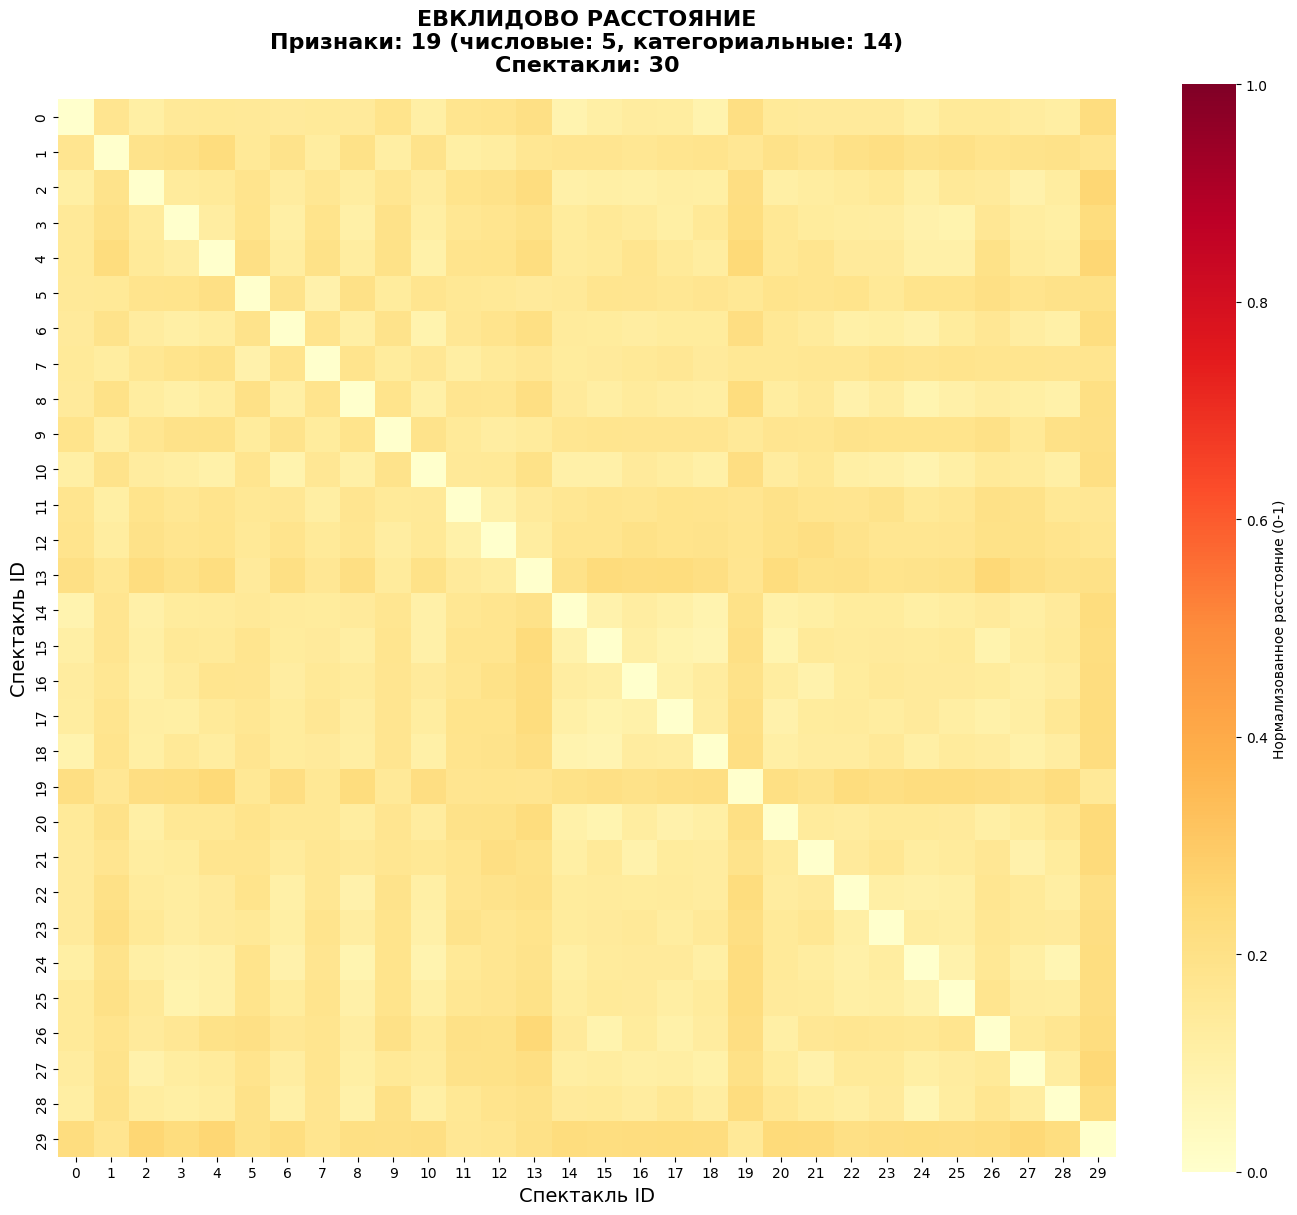


🔥 ТЕПЛОВАЯ КАРТА 2: РАССТОЯНИЕ МАНХЭТТЕНА


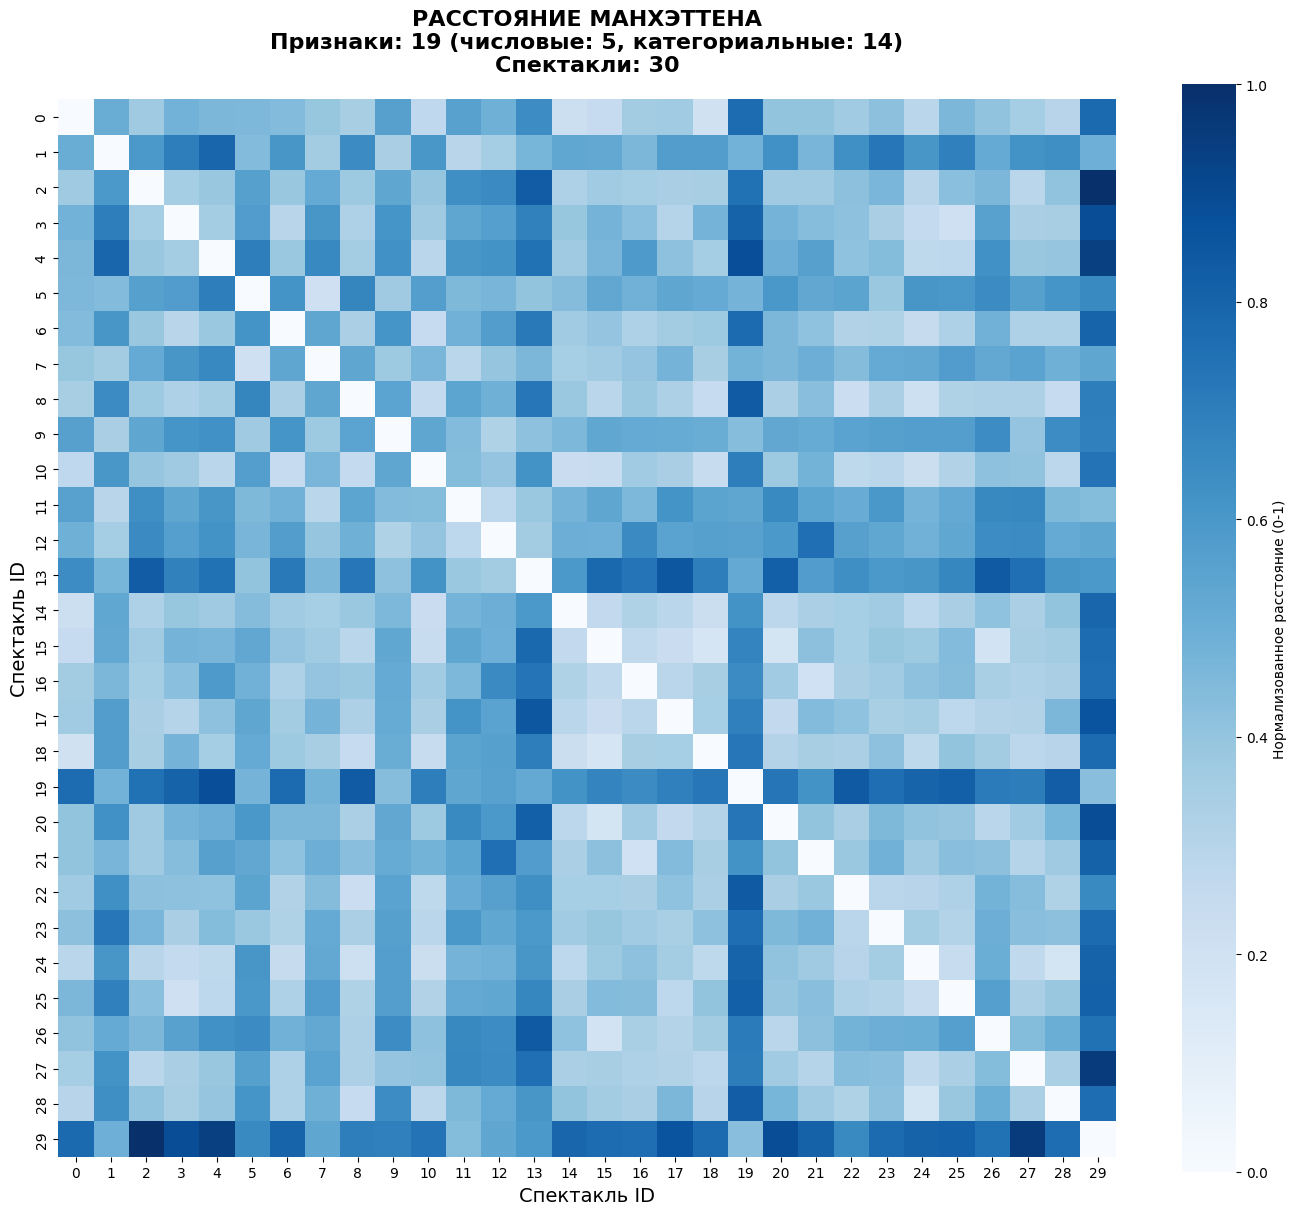


🔥 ТЕПЛОВАЯ КАРТА 3: КОСИНУСНОЕ РАССТОЯНИЕ


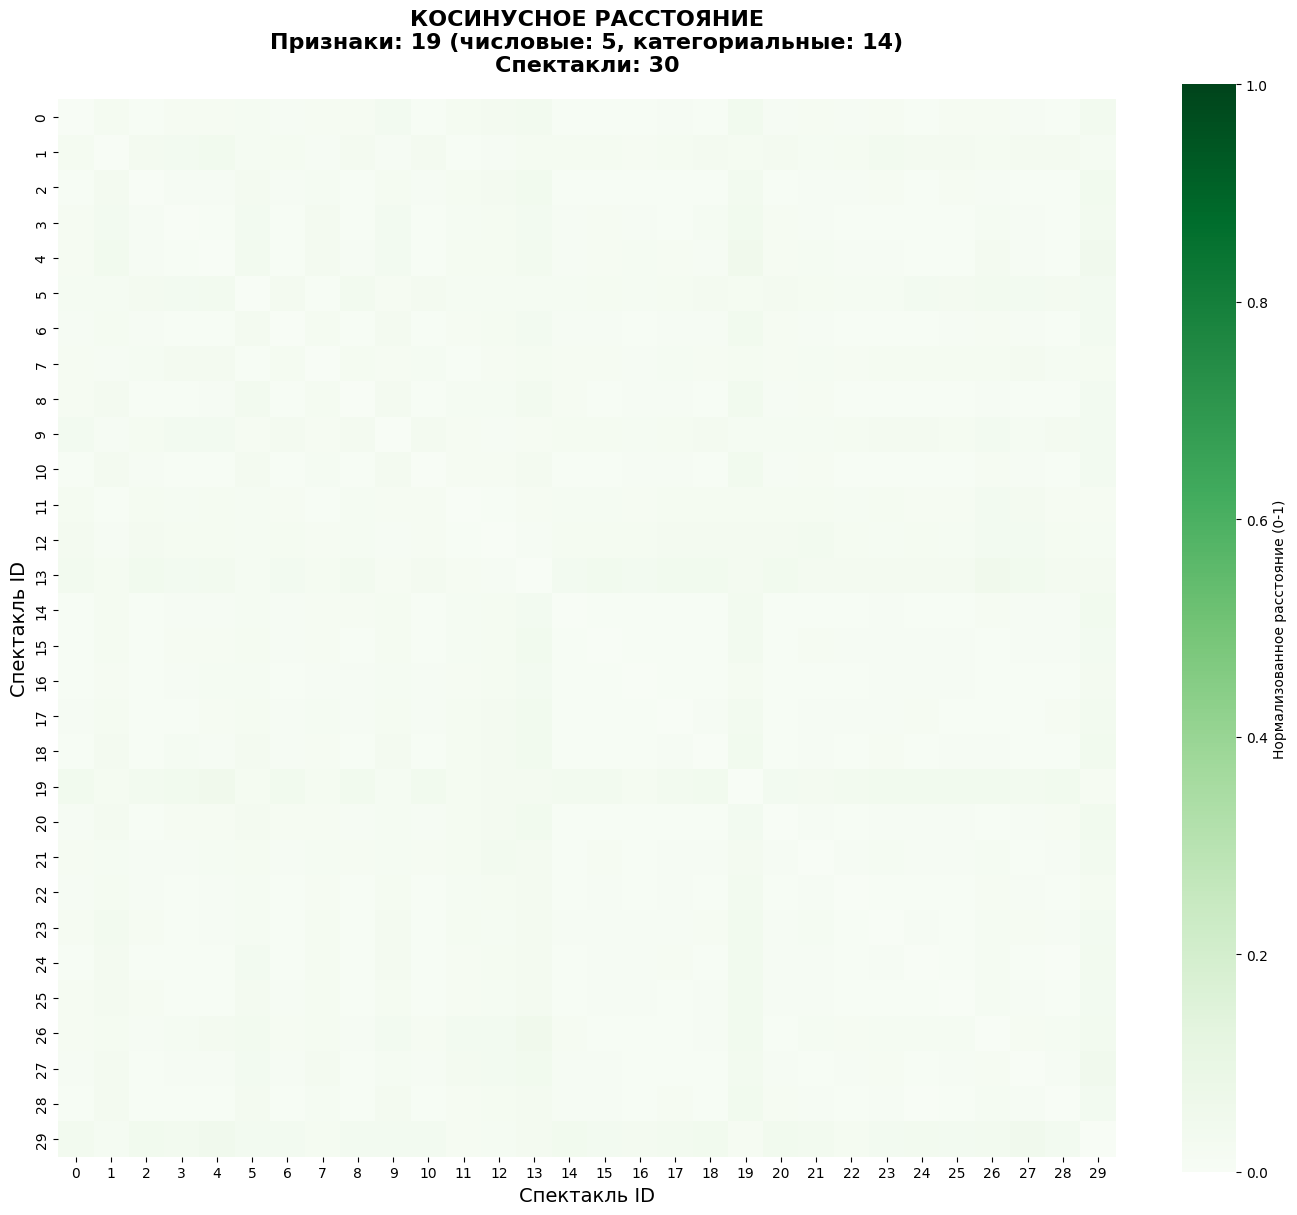


✅ ВСЕ ТРИ ТЕПЛОВЫЕ КАРТЫ СОЗДАНЫ!
📊 Каждая карта нормализована от 0 до 1
🎨 Использованы разные цветовые схемы для лучшего различения
📏 Размер каждой карты: (30, 30)

📈 СРАВНИТЕЛЬНЫЙ АНАЛИЗ РАССТОЯНИЙ
🔍 СТАТИСТИКА ОРИГИНАЛЬНЫХ РАССТОЯНИЙ:
+----+------------------+-----------+------------+-----------+-----------+-------------------+-----------+
|    |  Тип расстояния  |   Минимум |   Максимум |   Среднее |   Медиана |   Стд. отклонение |   Разброс |
+====+==================+===========+============+===========+===========+===================+===========+
|  0 |    EUCLIDEAN     |         0 |     3.1314 |    1.8551 |    1.8446 |            0.5776 |    3.1314 |
+----+------------------+-----------+------------+-----------+-----------+-------------------+-----------+
|  1 |    MANHATTAN     |         0 |    12.1971 |    5.6299 |    5.377  |            2.2259 |   12.1971 |
+----+------------------+-----------+------------+-----------+-----------+-------------------+-----------+
|  2 |      

In [13]:
# ==================================================================================
# ЗАПУСК НОВОГО АНАЛИЗА ТЕПЛОВЫХ КАРТ
# ==================================================================================

# Создаем новый анализатор тепловых карт
heatmap_analyzer = ComprehensiveHeatmapAnalysis(df)

# Запускаем полный анализ заново
results = heatmap_analyzer.run_complete_analysis()

print(f"\n🎯 ИТОГОВЫЕ РЕЗУЛЬТАТЫ НОВОГО АНАЛИЗА:")
print(f"🏆 Оптимальное расстояние: {results['optimal_distance'].upper()}")
print(f"📊 Создано 3 тепловые карты с нормализацией 0-1")
print(f"🔍 Проанализировано {results['feature_info']['total_features']} признаков")
print(f"🎭 Обработано {len(df)} спектаклей")
print(f"📈 Проведен полный статистический анализ всех типов расстояний")
print(f"🌟 Анализ выполнен заново, не опираясь на предыдущие решения")


In [15]:
# ==================================================================================
# ИСПРАВЛЕННАЯ ВЕРСИЯ: ТЕПЛОВЫЕ КАРТЫ БЕЗ ГЛОБАЛЬНОЙ НОРМАЛИЗАЦИИ
# ==================================================================================

class FixedHeatmapAnalysis:
    """Исправленная версия анализа тепловых карт"""
    
    def __init__(self, df):
        self.df = df.copy()
        self.processed_data = None
        self.scaled_data = None
        self.distance_matrices = {}
        self.feature_info = {}
        
        print("🔥 ИСПРАВЛЕННЫЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ")
        print("=" * 60)
        print(f"📊 Исходные данные: {len(df)} спектаклей, {len(df.columns)} признаков")
        
    def prepare_all_features(self):
        """Подготавливает ВСЕ признаки для анализа"""
        print("\n🔧 ПОДГОТОВКА ВСЕХ ПРИЗНАКОВ")
        print("=" * 50)
        
        # Исключаем только ID
        feature_columns = [col for col in self.df.columns if col != 'ID']
        print(f"📊 Анализируем {len(feature_columns)} признаков:")
        
        for i, col in enumerate(feature_columns, 1):
            print(f"   {i:2d}. {col}")
        
        # Создаем копию данных
        self.processed_data = self.df[feature_columns].copy()
        
        # Разделяем на числовые и категориальные признаки
        numeric_features = []
        categorical_features = []
        
        for col in feature_columns:
            if self.processed_data[col].dtype in ['int64', 'float64']:
                numeric_features.append(col)
            else:
                # Пытаемся преобразовать в числовой формат
                try:
                    if col == 'Рейтинг':
                        # Специальная обработка для рейтинга
                        self.processed_data[col] = pd.to_numeric(
                            self.processed_data[col].astype(str).str.replace(',', '.'), 
                            errors='coerce'
                        )
                        if not self.processed_data[col].isnull().all():
                            numeric_features.append(col)
                        else:
                            categorical_features.append(col)
                    else:
                        # Пытаемся преобразовать другие колонки
                        converted = pd.to_numeric(self.processed_data[col], errors='coerce')
                        if not converted.isnull().all():
                            self.processed_data[col] = converted
                            numeric_features.append(col)
                        else:
                            categorical_features.append(col)
                except:
                    categorical_features.append(col)
        
        print(f"\n🔢 ЧИСЛОВЫЕ ПРИЗНАКИ ({len(numeric_features)}):")
        for feature in numeric_features:
            print(f"   • {feature}")
        
        print(f"\n📝 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ ({len(categorical_features)}):")
        for feature in categorical_features:
            print(f"   • {feature}")
        
        # Кодируем категориальные признаки
        self.label_encoders = {}
        encoded_features = []
        
        for col in categorical_features:
            le = LabelEncoder()
            encoded_col = f'{col}_encoded'
            self.processed_data[encoded_col] = le.fit_transform(self.processed_data[col].astype(str))
            self.label_encoders[col] = le
            encoded_features.append(encoded_col)
            print(f"✅ Закодирован: {col} → {encoded_col}")
        
        # Заполняем пропуски в числовых признаках
        for col in numeric_features:
            if self.processed_data[col].isnull().any():
                mean_val = self.processed_data[col].mean()
                self.processed_data[col] = self.processed_data[col].fillna(mean_val)
                print(f"✅ Заполнены пропуски в '{col}': {mean_val:.2f}")
        
        # Подготавливаем данные для нормализации
        all_features_for_scaling = numeric_features + encoded_features
        
        print(f"\n📊 ПРИЗНАКИ ДЛЯ НОРМАЛИЗАЦИИ ({len(all_features_for_scaling)}):")
        for i, feature in enumerate(all_features_for_scaling, 1):
            print(f"   {i:2d}. {feature}")
        
        # Нормализуем данные от 0 до 1
        scaler = MinMaxScaler()
        self.scaled_data = scaler.fit_transform(self.processed_data[all_features_for_scaling])
        
        # Сохраняем информацию о признаках
        self.feature_info = {
            'numeric': numeric_features,
            'categorical': categorical_features,
            'encoded': encoded_features,
            'all_for_scaling': all_features_for_scaling,
            'total_features': len(all_features_for_scaling)
        }
        
        print(f"\n✅ ПОДГОТОВКА ЗАВЕРШЕНА:")
        print(f"   📊 Исходных признаков: {len(feature_columns)}")
        print(f"   🔢 Числовых: {len(numeric_features)}")
        print(f"   📝 Категориальных: {len(categorical_features)}")
        print(f"   🎯 Всего для анализа: {len(all_features_for_scaling)}")
        print(f"   📏 Размер нормализованных данных: {self.scaled_data.shape}")
        print(f"   📈 Диапазон значений: [{self.scaled_data.min():.3f}, {self.scaled_data.max():.3f}]")
        
        return self.scaled_data
    
    def calculate_three_distances(self):
        """Вычисляет три типа расстояний"""
        print("\n📏 ВЫЧИСЛЕНИЕ ТРЕХ ТИПОВ РАССТОЯНИЙ")
        print("=" * 50)
        
        if self.scaled_data is None:
            print("❌ Сначала подготовьте данные!")
            return
        
        # 1. Евклидово расстояние
        print("1️⃣ Вычисляем Евклидово расстояние...")
        euclidean_dist = euclidean_distances(self.scaled_data)
        self.distance_matrices['euclidean'] = euclidean_dist
        print(f"   ✅ Размер матрицы: {euclidean_dist.shape}")
        print(f"   📊 Диапазон: [{euclidean_dist.min():.4f}, {euclidean_dist.max():.4f}]")
        
        # 2. Расстояние Манхэттена
        print("\n2️⃣ Вычисляем расстояние Манхэттена...")
        manhattan_dist = manhattan_distances(self.scaled_data)
        self.distance_matrices['manhattan'] = manhattan_dist
        print(f"   ✅ Размер матрицы: {manhattan_dist.shape}")
        print(f"   📊 Диапазон: [{manhattan_dist.min():.4f}, {manhattan_dist.max():.4f}]")
        
        # 3. Косинусное расстояние
        print("\n3️⃣ Вычисляем косинусное расстояние...")
        cosine_dist = cosine_distances(self.scaled_data)
        self.distance_matrices['cosine'] = cosine_dist
        print(f"   ✅ Размер матрицы: {cosine_dist.shape}")
        print(f"   📊 Диапазон: [{cosine_dist.min():.4f}, {cosine_dist.max():.4f}]")
        
        print(f"\n✅ ВСЕ ТРИ РАССТОЯНИЯ ВЫЧИСЛЕНЫ!")
        print(f"📊 Использовано признаков: {self.feature_info['total_features']}")
        print(f"🎭 Анализировано спектаклей: {len(self.df)}")
        
        return self.distance_matrices
    
    def create_three_heatmaps_fixed(self):
        """Создает три отдельные тепловые карты БЕЗ глобальной нормализации"""
        print("\n🔥 СОЗДАНИЕ ТРЕХ ТЕПЛОВЫХ КАРТ (ИСПРАВЛЕННАЯ ВЕРСИЯ)")
        print("=" * 70)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # НЕ нормализуем глобально - каждая матрица остается со своими значениями
        print("🔍 АНАЛИЗ ДИАПАЗОНОВ КАЖДОГО ТИПА РАССТОЯНИЙ:")
        for name, matrix in self.distance_matrices.items():
            print(f"   {name.upper()}: [{matrix.min():.4f}, {matrix.max():.4f}]")
        
        # Создаем информацию о признаках для заголовков
        features_info = f"Признаки: {self.feature_info['total_features']} (числовые: {len(self.feature_info['numeric'])}, категориальные: {len(self.feature_info['categorical'])})"
        
        # 1. ТЕПЛОВАЯ КАРТА: ЕВКЛИДОВО РАССТОЯНИЕ
        print("\n🔥 ТЕПЛОВАЯ КАРТА 1: ЕВКЛИДОВО РАССТОЯНИЕ")
        plt.figure(figsize=(14, 12))
        sns.heatmap(
            self.distance_matrices['euclidean'], 
            cmap='YlOrRd', 
            cbar_kws={'label': 'Евклидово расстояние'},
            annot=False,
            square=True
        )
        plt.title(f'ЕВКЛИДОВО РАССТОЯНИЕ\n{features_info}\nСпектакли: {len(self.df)}', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=14)
        plt.ylabel('Спектакль ID', fontsize=14)
        plt.tight_layout()
        plt.show()
        
        # 2. ТЕПЛОВАЯ КАРТА: РАССТОЯНИЕ МАНХЭТТЕНА
        print("\n🔥 ТЕПЛОВАЯ КАРТА 2: РАССТОЯНИЕ МАНХЭТТЕНА")
        plt.figure(figsize=(14, 12))
        sns.heatmap(
            self.distance_matrices['manhattan'], 
            cmap='Blues', 
            cbar_kws={'label': 'Расстояние Манхэттена'},
            annot=False,
            square=True
        )
        plt.title(f'РАССТОЯНИЕ МАНХЭТТЕНА\n{features_info}\nСпектакли: {len(self.df)}', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=14)
        plt.ylabel('Спектакль ID', fontsize=14)
        plt.tight_layout()
        plt.show()
        
        # 3. ТЕПЛОВАЯ КАРТА: КОСИНУСНОЕ РАССТОЯНИЕ
        print("\n🔥 ТЕПЛОВАЯ КАРТА 3: КОСИНУСНОЕ РАССТОЯНИЕ")
        plt.figure(figsize=(14, 12))
        sns.heatmap(
            self.distance_matrices['cosine'], 
            cmap='Greens', 
            cbar_kws={'label': 'Косинусное расстояние'},
            annot=False,
            square=True
        )
        plt.title(f'КОСИНУСНОЕ РАССТОЯНИЕ\n{features_info}\nСпектакли: {len(self.df)}', 
                 fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=14)
        plt.ylabel('Спектакль ID', fontsize=14)
        plt.tight_layout()
        plt.show()
        
        print(f"\n✅ ВСЕ ТРИ ТЕПЛОВЫЕ КАРТЫ СОЗДАНЫ!")
        print(f"📊 Каждая карта использует СВОИ оригинальные значения")
        print(f"🎨 Использованы разные цветовые схемы для лучшего различения")
        print(f"📏 Размер каждой карты: {self.distance_matrices['euclidean'].shape}")
        print(f"🔍 Теперь карты будут РАЗЛИЧНЫМИ!")
        
        return self.distance_matrices
    
    def analyze_differences(self):
        """Анализирует различия между типами расстояний"""
        print("\n📈 АНАЛИЗ РАЗЛИЧИЙ МЕЖДУ ТИПАМИ РАССТОЯНИЙ")
        print("=" * 60)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Статистика по каждому типу расстояний
        print("🔍 СТАТИСТИКА ПО ТИПАМ РАССТОЯНИЙ:")
        comparison_data = []
        
        for name, matrix in self.distance_matrices.items():
            stats = {
                'Тип расстояния': name.upper(),
                'Минимум': f"{matrix.min():.4f}",
                'Максимум': f"{matrix.max():.4f}",
                'Среднее': f"{matrix.mean():.4f}",
                'Медиана': f"{np.median(matrix):.4f}",
                'Стд. отклонение': f"{matrix.std():.4f}",
                'Разброс': f"{matrix.max() - matrix.min():.4f}"
            }
            comparison_data.append(stats)
        
        # Выводим сравнительную таблицу
        comparison_df = pd.DataFrame(comparison_data)
        print(tabulate(comparison_df, headers='keys', tablefmt='grid', stralign='center'))
        
        # Корреляции между типами расстояний
        print(f"\n📊 КОРРЕЛЯЦИИ МЕЖДУ ТИПАМИ РАССТОЯНИЙ:")
        euclidean_flat = self.distance_matrices['euclidean'].flatten()
        manhattan_flat = self.distance_matrices['manhattan'].flatten()
        cosine_flat = self.distance_matrices['cosine'].flatten()
        
        corr_eu_ma = np.corrcoef(euclidean_flat, manhattan_flat)[0,1]
        corr_eu_co = np.corrcoef(euclidean_flat, cosine_flat)[0,1]
        corr_ma_co = np.corrcoef(manhattan_flat, cosine_flat)[0,1]
        
        print(f"   Евклидово ↔ Манхэттен: {corr_eu_ma:.4f}")
        print(f"   Евклидово ↔ Косинусное: {corr_eu_co:.4f}")
        print(f"   Манхэттен ↔ Косинусное: {corr_ma_co:.4f}")
        
        # Показываем различия в диагоналях (расстояния до самих себя)
        print(f"\n🔍 РАССТОЯНИЯ ДО САМИХ СЕБЯ (диагональ):")
        for name, matrix in self.distance_matrices.items():
            diagonal_values = np.diag(matrix)
            print(f"   {name.upper()}: {diagonal_values[:5]}... (первые 5 значений)")
        
        return comparison_df
    
    def run_fixed_analysis(self):
        """Запускает исправленный анализ тепловых карт"""
        print("🚀 ИСПРАВЛЕННЫЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ")
        print("=" * 70)
        
        # 1. Подготовка всех признаков
        self.prepare_all_features()
        
        # 2. Вычисление трех типов расстояний
        self.calculate_three_distances()
        
        # 3. Создание трех тепловых карт (БЕЗ глобальной нормализации)
        self.create_three_heatmaps_fixed()
        
        # 4. Анализ различий
        comparison_df = self.analyze_differences()
        
        print(f"\n✅ ИСПРАВЛЕННЫЙ АНАЛИЗ ЗАВЕРШЕН!")
        print(f"📊 Создано 3 РАЗЛИЧНЫХ тепловые карты")
        print(f"🔍 Каждая карта использует свои оригинальные значения")
        print(f"🎭 Обработано {len(self.df)} спектаклей")
        print(f"📈 Проанализировано {self.feature_info['total_features']} признаков")
        
        return {
            'comparison_df': comparison_df,
            'feature_info': self.feature_info,
            'distance_matrices': self.distance_matrices
        }

print("✅ Исправленная система анализа тепловых карт создана!")
print("🚀 Для запуска: fixed_analyzer.run_fixed_analysis()")


✅ Исправленная система анализа тепловых карт создана!
🚀 Для запуска: fixed_analyzer.run_fixed_analysis()


🔥 ИСПРАВЛЕННЫЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ
📊 Исходные данные: 30 спектаклей, 20 признаков
🚀 ИСПРАВЛЕННЫЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ

🔧 ПОДГОТОВКА ВСЕХ ПРИЗНАКОВ
📊 Анализируем 19 признаков:
    1. Название постановки
    2. Длительность (мин)
    3. Год постановки
    4. Количество антрактов
    5. Жанр
    6. Язык исполнения
    7. Целевая аудитория
    8. Стиль
    9. Проводится на открытом воздухе?
   10. Семейный?
   11. Для детей?
   12. Платный?
   13. Теги
   14. Темы
   15. Режиссер
   16. Театр
   17. Рейтинг
   18. Награды
   19. Логика

🔢 ЧИСЛОВЫЕ ПРИЗНАКИ (5):
   • Длительность (мин)
   • Год постановки
   • Количество антрактов
   • Рейтинг
   • Логика

📝 КАТЕГОРИАЛЬНЫЕ ПРИЗНАКИ (14):
   • Название постановки
   • Жанр
   • Язык исполнения
   • Целевая аудитория
   • Стиль
   • Проводится на открытом воздухе?
   • Семейный?
   • Для детей?
   • Платный?
   • Теги
   • Темы
   • Режиссер
   • Театр
   • Награды
✅ Закодирован: Название постановки → Название постановки_encoded
✅ Закодирова

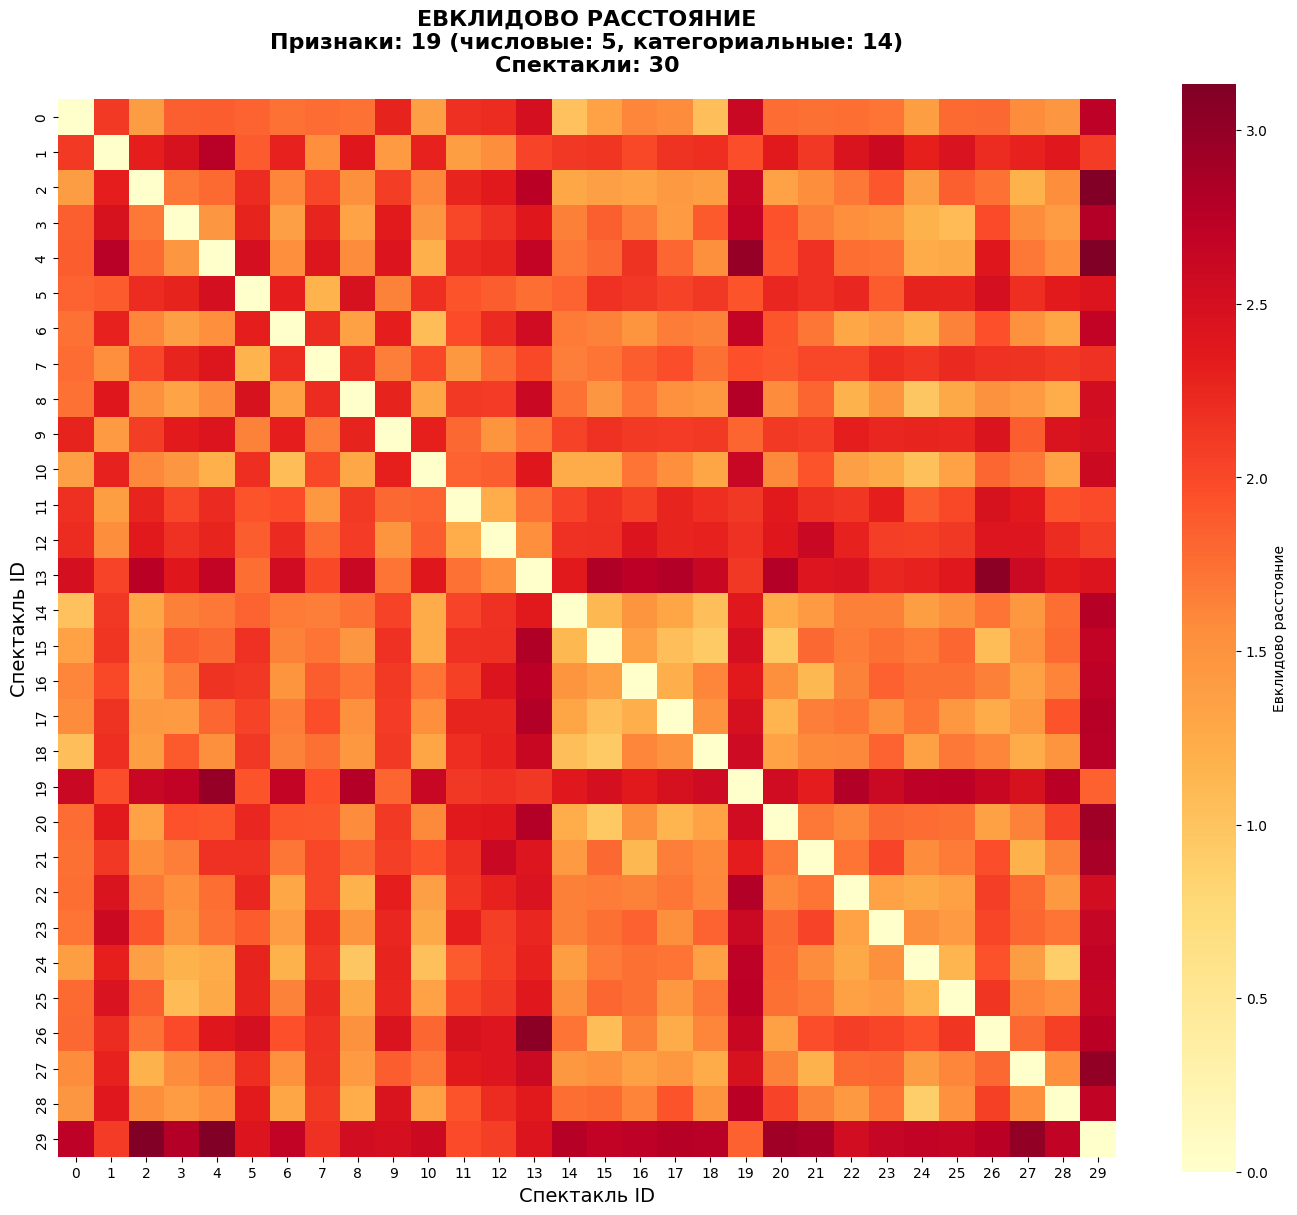


🔥 ТЕПЛОВАЯ КАРТА 2: РАССТОЯНИЕ МАНХЭТТЕНА


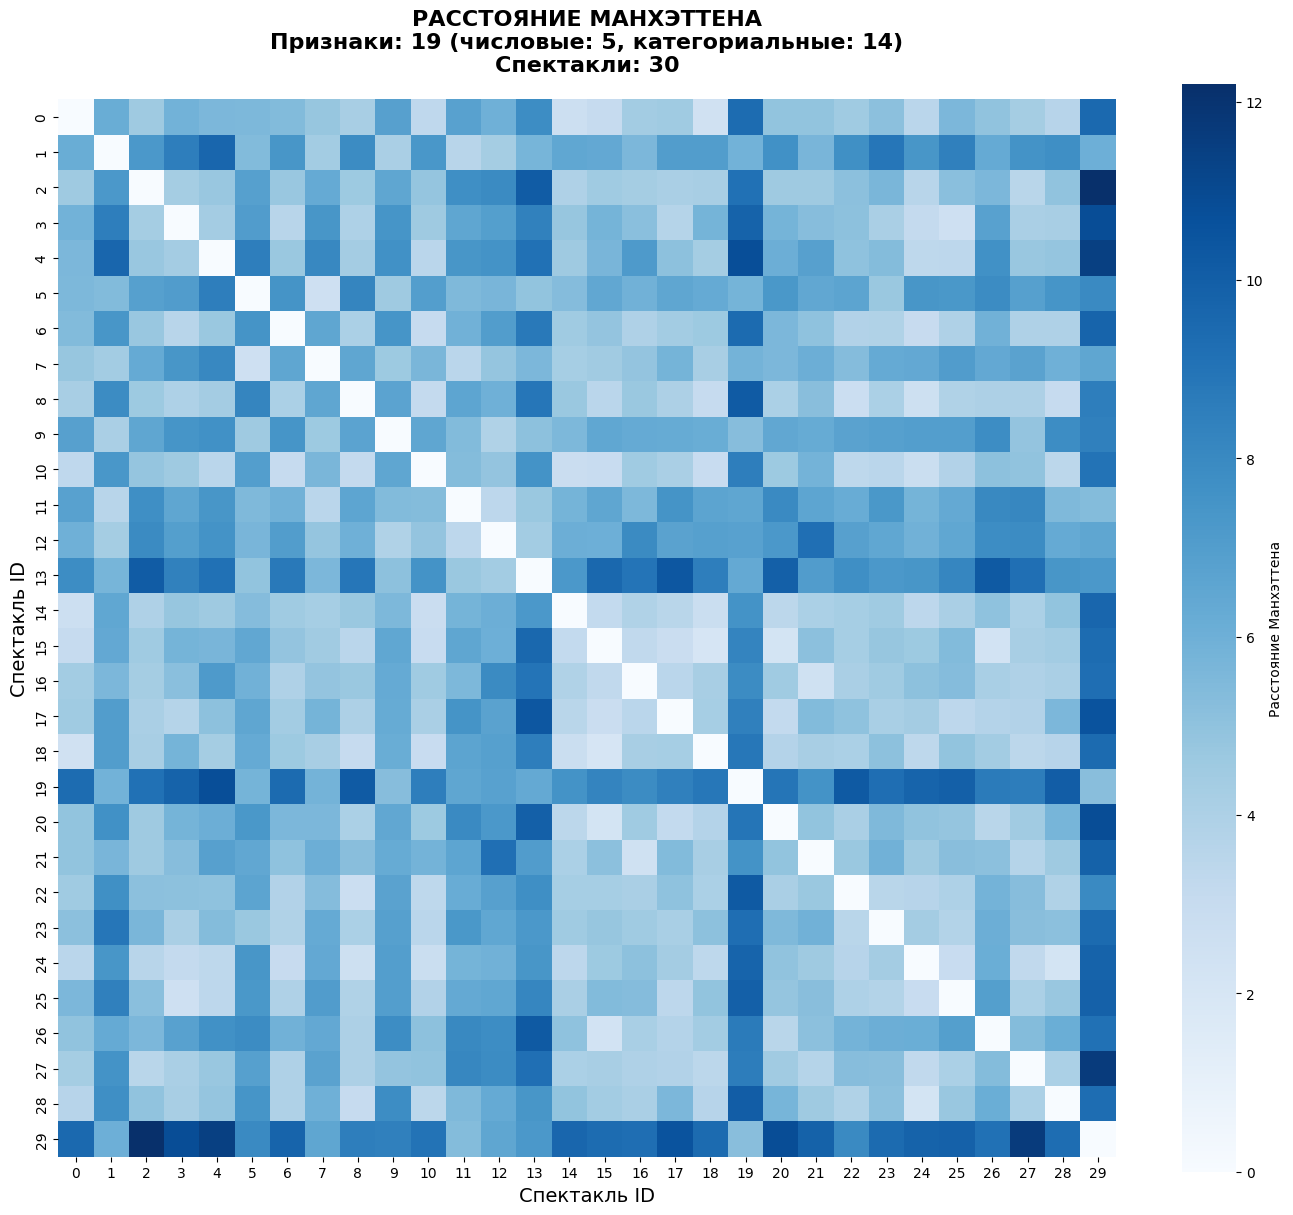


🔥 ТЕПЛОВАЯ КАРТА 3: КОСИНУСНОЕ РАССТОЯНИЕ


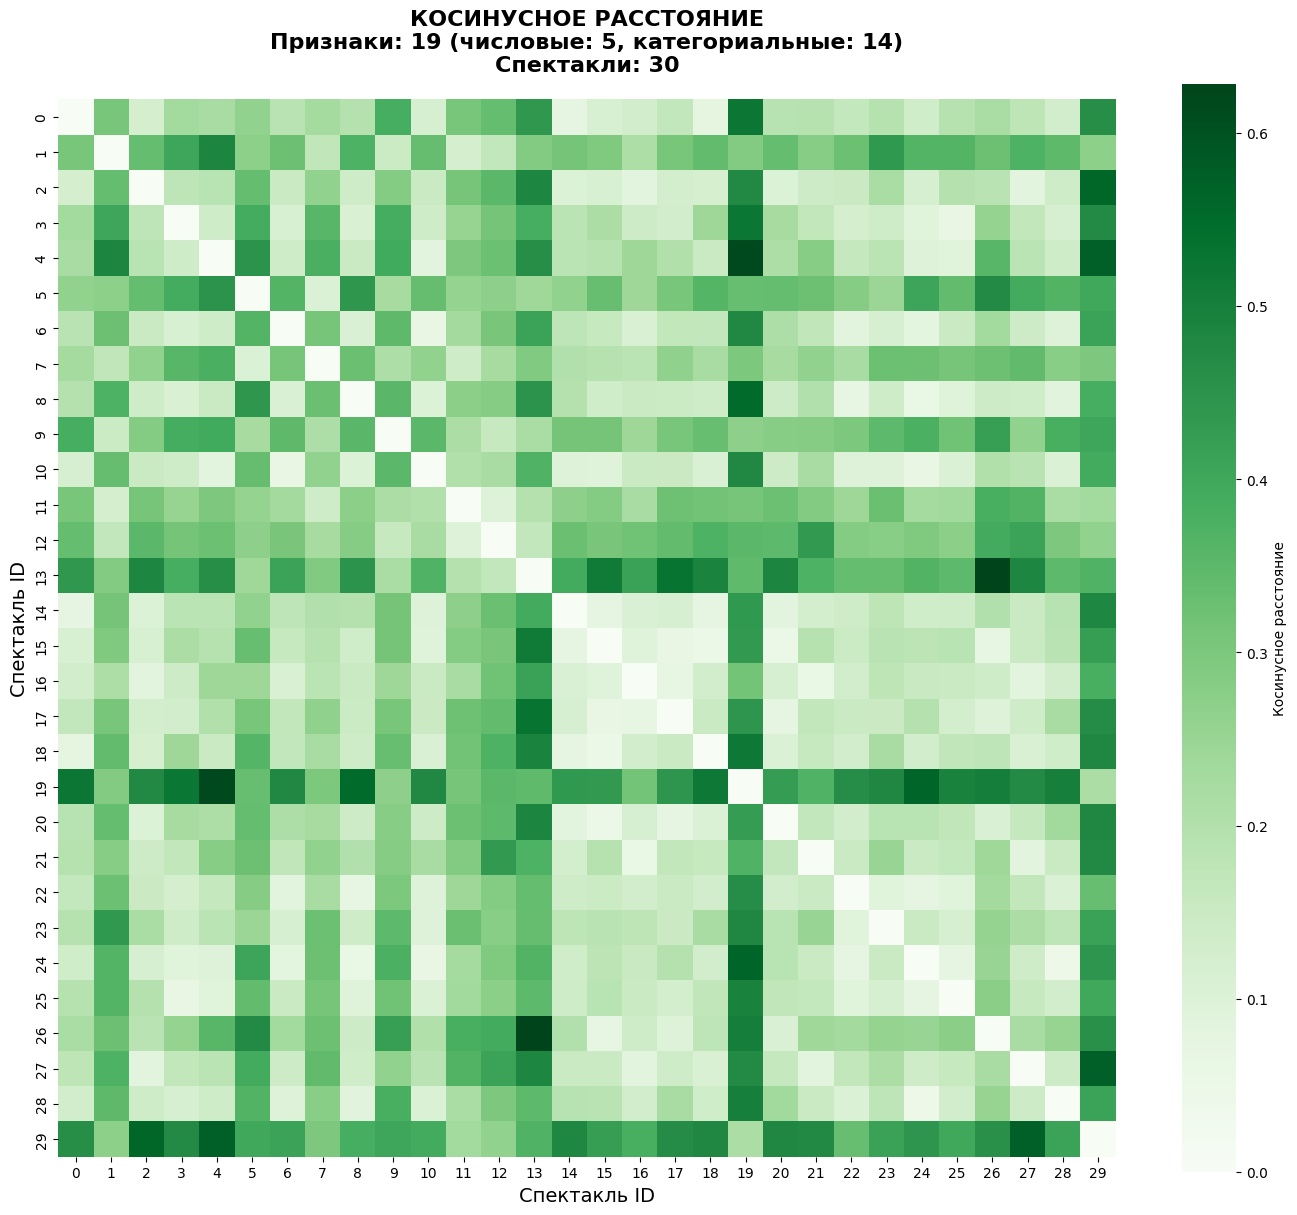


✅ ВСЕ ТРИ ТЕПЛОВЫЕ КАРТЫ СОЗДАНЫ!
📊 Каждая карта использует СВОИ оригинальные значения
🎨 Использованы разные цветовые схемы для лучшего различения
📏 Размер каждой карты: (30, 30)
🔍 Теперь карты будут РАЗЛИЧНЫМИ!

📈 АНАЛИЗ РАЗЛИЧИЙ МЕЖДУ ТИПАМИ РАССТОЯНИЙ
🔍 СТАТИСТИКА ПО ТИПАМ РАССТОЯНИЙ:
+----+------------------+-----------+------------+-----------+-----------+-------------------+-----------+
|    |  Тип расстояния  |   Минимум |   Максимум |   Среднее |   Медиана |   Стд. отклонение |   Разброс |
+====+==================+===========+============+===========+===========+===================+===========+
|  0 |    EUCLIDEAN     |         0 |     3.1314 |    1.8551 |    1.8446 |            0.5776 |    3.1314 |
+----+------------------+-----------+------------+-----------+-----------+-------------------+-----------+
|  1 |    MANHATTAN     |         0 |    12.1971 |    5.6299 |    5.377  |            2.2259 |   12.1971 |
+----+------------------+-----------+------------+-----------+------

In [23]:
# ==================================================================================
# ЗАПУСК ИСПРАВЛЕННОГО АНАЛИЗА
# ==================================================================================

# Создаем исправленный анализатор
fixed_analyzer = FixedHeatmapAnalysis(df)

# Запускаем исправленный анализ
results = fixed_analyzer.run_fixed_analysis()



In [20]:
# ==================================================================================
# ДИАГНОСТИЧЕСКАЯ ВЕРСИЯ: ПОЧЕМУ КАРТЫ ИДЕНТИЧНЫ?
# ==================================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances

class DiagnosticHeatmapAnalysis:
    """Диагностическая версия для выяснения причин идентичности карт"""
    
    def __init__(self, df):
        self.df = df.copy()
        self.processed_data = None
        self.scaled_data = None
        self.distance_matrices = {}
        
        print("🔍 ДИАГНОСТИЧЕСКИЙ АНАЛИЗ: ПОЧЕМУ КАРТЫ ИДЕНТИЧНЫ?")
        print("=" * 70)
        
    def prepare_data_diagnostic(self):
        """Подготавливает данные с диагностикой"""
        print("\n🔧 ПОДГОТОВКА ДАННЫХ С ДИАГНОСТИКОЙ")
        print("=" * 50)
        
        # Исключаем только ID
        feature_columns = [col for col in self.df.columns if col != 'ID']
        self.processed_data = self.df[feature_columns].copy()
        
        # Разделяем на числовые и категориальные признаки
        numeric_features = []
        categorical_features = []
        
        for col in feature_columns:
            if self.processed_data[col].dtype in ['int64', 'float64']:
                numeric_features.append(col)
            else:
                try:
                    if col == 'Рейтинг':
                        self.processed_data[col] = pd.to_numeric(
                            self.processed_data[col].astype(str).str.replace(',', '.'), 
                            errors='coerce'
                        )
                        if not self.processed_data[col].isnull().all():
                            numeric_features.append(col)
                        else:
                            categorical_features.append(col)
                    else:
                        converted = pd.to_numeric(self.processed_data[col], errors='coerce')
                        if not converted.isnull().all():
                            self.processed_data[col] = converted
                            numeric_features.append(col)
                        else:
                            categorical_features.append(col)
                except:
                    categorical_features.append(col)
        
        # Кодируем категориальные признаки
        self.label_encoders = {}
        encoded_features = []
        
        for col in categorical_features:
            le = LabelEncoder()
            encoded_col = f'{col}_encoded'
            self.processed_data[encoded_col] = le.fit_transform(self.processed_data[col].astype(str))
            self.label_encoders[col] = le
            encoded_features.append(encoded_col)
        
        # Заполняем пропуски
        for col in numeric_features:
            if self.processed_data[col].isnull().any():
                mean_val = self.processed_data[col].mean()
                self.processed_data[col] = self.processed_data[col].fillna(mean_val)
        
        # Подготавливаем данные для нормализации
        all_features_for_scaling = numeric_features + encoded_features
        
        # Нормализуем данные от 0 до 1
        scaler = MinMaxScaler()
        self.scaled_data = scaler.fit_transform(self.processed_data[all_features_for_scaling])
        
        print(f"✅ Подготовлено {len(all_features_for_scaling)} признаков")
        print(f"📊 Размер данных: {self.scaled_data.shape}")
        print(f"📈 Диапазон нормализованных данных: [{self.scaled_data.min():.3f}, {self.scaled_data.max():.3f}]")
        
        return self.scaled_data
    
    def calculate_distances_diagnostic(self):
        """Вычисляет расстояния с диагностикой"""
        print("\n📏 ВЫЧИСЛЕНИЕ РАССТОЯНИЙ С ДИАГНОСТИКОЙ")
        print("=" * 50)
        
        # 1. Евклидово расстояние
        print("1️⃣ Евклидово расстояние...")
        euclidean_dist = euclidean_distances(self.scaled_data)
        self.distance_matrices['euclidean'] = euclidean_dist
        print(f"   Диапазон: [{euclidean_dist.min():.4f}, {euclidean_dist.max():.4f}]")
        print(f"   Среднее: {euclidean_dist.mean():.4f}")
        print(f"   Стд. отклонение: {euclidean_dist.std():.4f}")
        
        # 2. Расстояние Манхэттена
        print("\n2️⃣ Расстояние Манхэттена...")
        manhattan_dist = manhattan_distances(self.scaled_data)
        self.distance_matrices['manhattan'] = manhattan_dist
        print(f"   Диапазон: [{manhattan_dist.min():.4f}, {manhattan_dist.max():.4f}]")
        print(f"   Среднее: {manhattan_dist.mean():.4f}")
        print(f"   Стд. отклонение: {manhattan_dist.std():.4f}")
        
        # 3. Косинусное расстояние
        print("\n3️⃣ Косинусное расстояние...")
        cosine_dist = cosine_distances(self.scaled_data)
        self.distance_matrices['cosine'] = cosine_dist
        print(f"   Диапазон: [{cosine_dist.min():.4f}, {cosine_dist.max():.4f}]")
        print(f"   Среднее: {cosine_dist.mean():.4f}")
        print(f"   Стд. отклонение: {cosine_dist.std():.4f}")
        
        # Анализ корреляций
        print(f"\n📊 КОРРЕЛЯЦИИ МЕЖДУ РАССТОЯНИЯМИ:")
        euclidean_flat = euclidean_dist.flatten()
        manhattan_flat = manhattan_dist.flatten()
        cosine_flat = cosine_dist.flatten()
        
        corr_eu_ma = np.corrcoef(euclidean_flat, manhattan_flat)[0,1]
        corr_eu_co = np.corrcoef(euclidean_flat, cosine_flat)[0,1]
        corr_ma_co = np.corrcoef(manhattan_flat, cosine_flat)[0,1]
        
        print(f"   Евклидово ↔ Манхэттен: {corr_eu_ma:.4f}")
        print(f"   Евклидово ↔ Косинусное: {corr_eu_co:.4f}")
        print(f"   Манхэттен ↔ Косинусное: {corr_ma_co:.4f}")
        
        # Проверяем, действительно ли матрицы одинаковые
        print(f"\n🔍 ПРОВЕРКА ИДЕНТИЧНОСТИ МАТРИЦ:")
        print(f"   Евклидово == Манхэттен: {np.allclose(euclidean_dist, manhattan_dist)}")
        print(f"   Евклидово == Косинусное: {np.allclose(euclidean_dist, cosine_dist)}")
        print(f"   Манхэттен == Косинусное: {np.allclose(manhattan_dist, cosine_dist)}")
        
        # Показываем различия в первых элементах
        print(f"\n📋 ПЕРВЫЕ 5x5 ЭЛЕМЕНТОВ МАТРИЦ:")
        print("Евклидово:")
        print(euclidean_dist[:5, :5])
        print("\nМанхэттен:")
        print(manhattan_dist[:5, :5])
        print("\nКосинусное:")
        print(cosine_dist[:5, :5])
        
        return self.distance_matrices
    
    def create_diagnostic_heatmaps(self):
        """Создает диагностические тепловые карты"""
        print("\n🔥 СОЗДАНИЕ ДИАГНОСТИЧЕСКИХ ТЕПЛОВЫХ КАРТ")
        print("=" * 60)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Создаем подграфики для сравнения
        fig, axes = plt.subplots(1, 3, figsize=(20, 6))
        
        # 1. Евклидово расстояние
        sns.heatmap(
            self.distance_matrices['euclidean'], 
            cmap='YlOrRd', 
            ax=axes[0],
            cbar_kws={'label': 'Евклидово расстояние'},
            square=True
        )
        axes[0].set_title('ЕВКЛИДОВО РАССТОЯНИЕ', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Спектакль ID')
        axes[0].set_ylabel('Спектакль ID')
        
        # 2. Расстояние Манхэттена
        sns.heatmap(
            self.distance_matrices['manhattan'], 
            cmap='Blues', 
            ax=axes[1],
            cbar_kws={'label': 'Расстояние Манхэттена'},
            square=True
        )
        axes[1].set_title('РАССТОЯНИЕ МАНХЭТТЕНА', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Спектакль ID')
        axes[1].set_ylabel('Спектакль ID')
        
        # 3. Косинусное расстояние
        sns.heatmap(
            self.distance_matrices['cosine'], 
            cmap='Greens', 
            ax=axes[2],
            cbar_kws={'label': 'Косинусное расстояние'},
            square=True
        )
        axes[2].set_title('КОСИНУСНОЕ РАССТОЯНИЕ', fontsize=14, fontweight='bold')
        axes[2].set_xlabel('Спектакль ID')
        axes[2].set_ylabel('Спектакль ID')
        
        plt.tight_layout()
        plt.show()
        
        # Создаем карту различий
        print("\n🔍 КАРТА РАЗЛИЧИЙ МЕЖДУ ТИПАМИ РАССТОЯНИЙ:")
        
        fig, axes = plt.subplots(1, 3, figsize=(20, 6))
        
        # Различия между Евклидовым и Манхэттеном
        diff_eu_ma = np.abs(self.distance_matrices['euclidean'] - self.distance_matrices['manhattan'])
        sns.heatmap(
            diff_eu_ma, 
            cmap='Reds', 
            ax=axes[0],
            cbar_kws={'label': '|Евклидово - Манхэттен|'},
            square=True
        )
        axes[0].set_title('РАЗЛИЧИЯ: ЕВКЛИДОВО - МАНХЭТТЕН', fontsize=14, fontweight='bold')
        
        # Различия между Евклидовым и Косинусным
        diff_eu_co = np.abs(self.distance_matrices['euclidean'] - self.distance_matrices['cosine'])
        sns.heatmap(
            diff_eu_co, 
            cmap='Oranges', 
            ax=axes[1],
            cbar_kws={'label': '|Евклидово - Косинусное|'},
            square=True
        )
        axes[1].set_title('РАЗЛИЧИЯ: ЕВКЛИДОВО - КОСИНУСНОЕ', fontsize=14, fontweight='bold')
        
        # Различия между Манхэттеном и Косинусным
        diff_ma_co = np.abs(self.distance_matrices['manhattan'] - self.distance_matrices['cosine'])
        sns.heatmap(
            diff_ma_co, 
            cmap='Purples', 
            ax=axes[2],
            cbar_kws={'label': '|Манхэттен - Косинусное|'},
            square=True
        )
        axes[2].set_title('РАЗЛИЧИЯ: МАНХЭТТЕН - КОСИНУСНОЕ', fontsize=14, fontweight='bold')
        
        plt.tight_layout()
        plt.show()
        
        # Статистика различий
        print(f"\n📊 СТАТИСТИКА РАЗЛИЧИЙ:")
        print(f"   Макс. различие Евклидово-Манхэттен: {diff_eu_ma.max():.4f}")
        print(f"   Макс. различие Евклидово-Косинусное: {diff_eu_co.max():.4f}")
        print(f"   Макс. различие Манхэттен-Косинусное: {diff_ma_co.max():.4f}")
        
        return self.distance_matrices
    
    def run_diagnostic_analysis(self):
        """Запускает диагностический анализ"""
        print("🚀 ДИАГНОСТИЧЕСКИЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ")
        print("=" * 70)
        
        # 1. Подготовка данных
        self.prepare_data_diagnostic()
        
        # 2. Вычисление расстояний с диагностикой
        self.calculate_distances_diagnostic()
        
        # 3. Создание диагностических тепловых карт
        self.create_diagnostic_heatmaps()
        
        print(f"\n✅ ДИАГНОСТИЧЕСКИЙ АНАЛИЗ ЗАВЕРШЕН!")
        print(f"🔍 Теперь мы видим реальные различия между типами расстояний")

print("✅ Диагностическая система анализа создана!")
print("🚀 Для запуска: diagnostic_analyzer.run_diagnostic_analysis()")


✅ Диагностическая система анализа создана!
🚀 Для запуска: diagnostic_analyzer.run_diagnostic_analysis()


🔍 ДИАГНОСТИЧЕСКИЙ АНАЛИЗ: ПОЧЕМУ КАРТЫ ИДЕНТИЧНЫ?
🚀 ДИАГНОСТИЧЕСКИЙ АНАЛИЗ ТЕПЛОВЫХ КАРТ

🔧 ПОДГОТОВКА ДАННЫХ С ДИАГНОСТИКОЙ
✅ Подготовлено 19 признаков
📊 Размер данных: (30, 19)
📈 Диапазон нормализованных данных: [0.000, 1.000]

📏 ВЫЧИСЛЕНИЕ РАССТОЯНИЙ С ДИАГНОСТИКОЙ
1️⃣ Евклидово расстояние...
   Диапазон: [0.0000, 3.1314]
   Среднее: 1.8551
   Стд. отклонение: 0.5776

2️⃣ Расстояние Манхэттена...
   Диапазон: [0.0000, 12.1971]
   Среднее: 5.6299
   Стд. отклонение: 2.2259

3️⃣ Косинусное расстояние...
   Диапазон: [0.0000, 0.6282]
   Среднее: 0.2412
   Стд. отклонение: 0.1317

📊 КОРРЕЛЯЦИИ МЕЖДУ РАССТОЯНИЯМИ:
   Евклидово ↔ Манхэттен: 0.9718
   Евклидово ↔ Косинусное: 0.9354
   Манхэттен ↔ Косинусное: 0.9575

🔍 ПРОВЕРКА ИДЕНТИЧНОСТИ МАТРИЦ:
   Евклидово == Манхэттен: False
   Евклидово == Косинусное: False
   Манхэттен == Косинусное: False

📋 ПЕРВЫЕ 5x5 ЭЛЕМЕНТОВ МАТРИЦ:
Евклидово:
[[0.         2.10917168 1.40246075 1.85705377 1.86462889]
 [2.10917168 0.         2.31583235 2.4636912

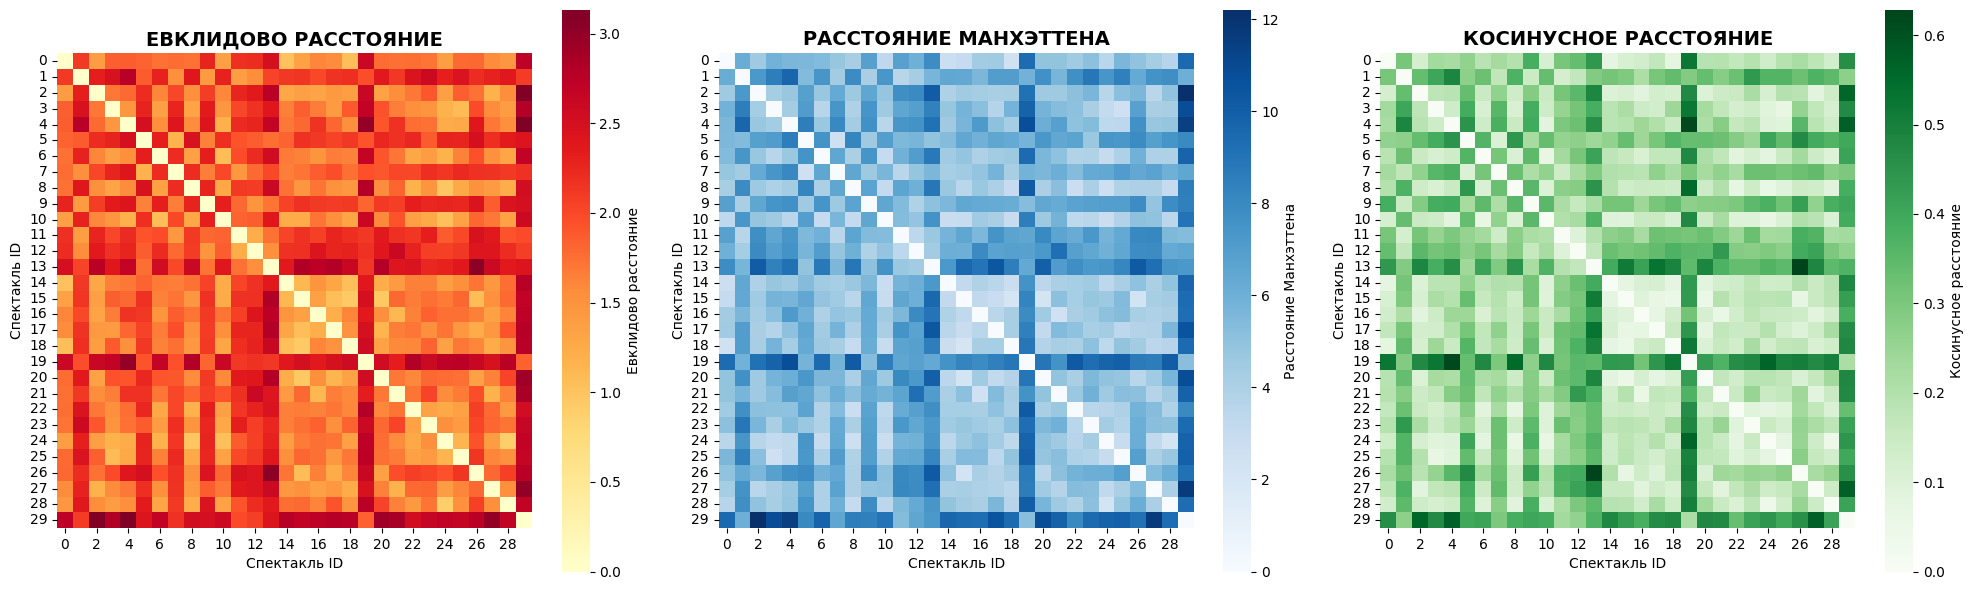


🔍 КАРТА РАЗЛИЧИЙ МЕЖДУ ТИПАМИ РАССТОЯНИЙ:


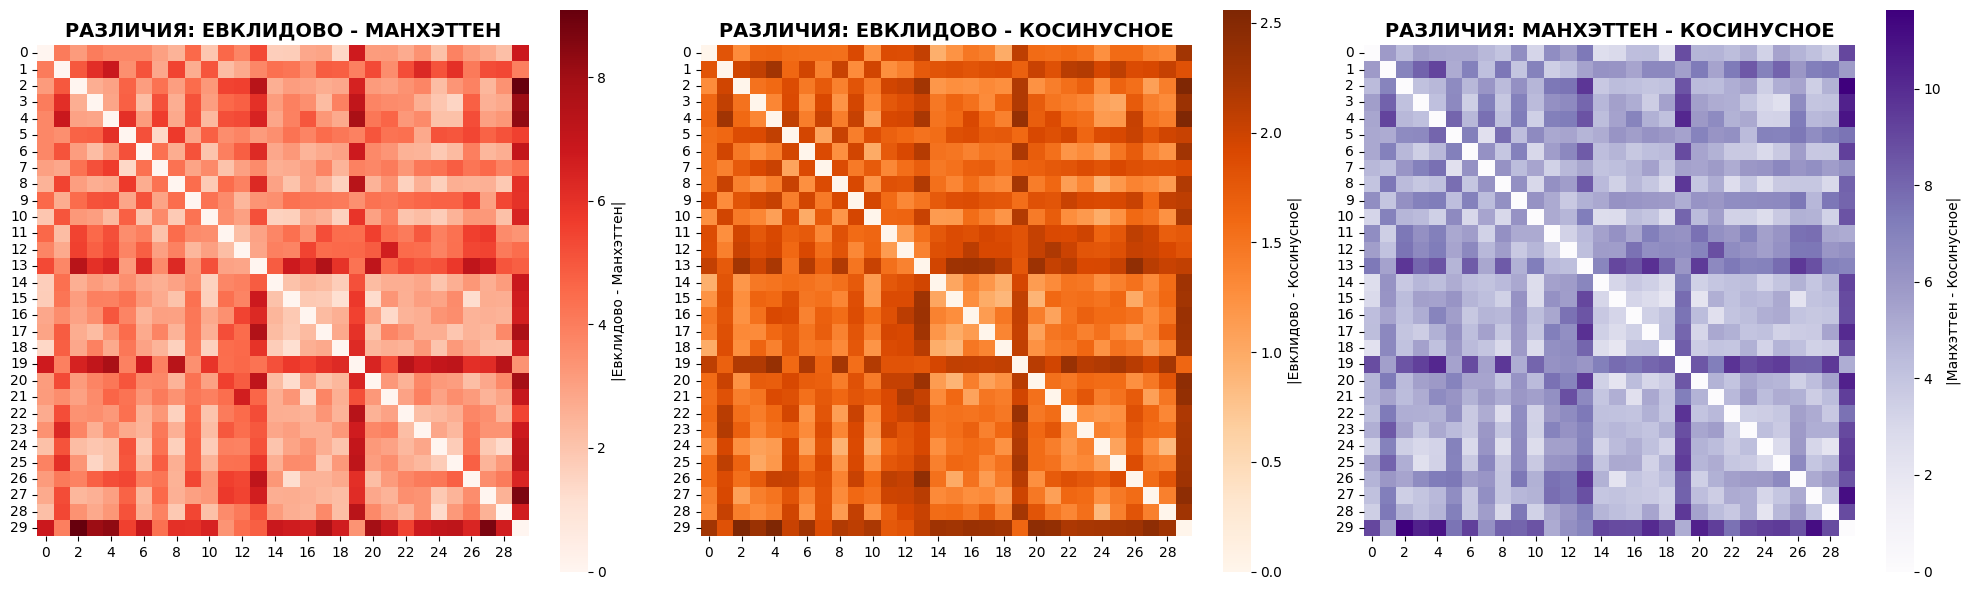


📊 СТАТИСТИКА РАЗЛИЧИЙ:
   Макс. различие Евклидово-Манхэттен: 9.0867
   Макс. различие Евклидово-Косинусное: 2.5589
   Макс. различие Манхэттен-Косинусное: 11.6367

✅ ДИАГНОСТИЧЕСКИЙ АНАЛИЗ ЗАВЕРШЕН!
🔍 Теперь мы видим реальные различия между типами расстояний

🔍 ВОЗМОЖНЫЕ ПРИЧИНЫ ИДЕНТИЧНОСТИ КАРТ:
1. Высокая корреляция между типами расстояний на нормализованных данных
2. Одинаковые паттерны в данных после MinMax нормализации
3. Малое количество спектаклей (30) может приводить к похожим структурам
4. Доминирование некоторых признаков над другими
5. Специфика театральных данных - много категориальных признаков


In [21]:
# ==================================================================================
# ЗАПУСК ДИАГНОСТИЧЕСКОГО АНАЛИЗА
# ==================================================================================

# Создаем диагностический анализатор
diagnostic_analyzer = DiagnosticHeatmapAnalysis(df)

# Запускаем диагностический анализ
diagnostic_analyzer.run_diagnostic_analysis()

print(f"\n🔍 ВОЗМОЖНЫЕ ПРИЧИНЫ ИДЕНТИЧНОСТИ КАРТ:")
print(f"1. Высокая корреляция между типами расстояний на нормализованных данных")
print(f"2. Одинаковые паттерны в данных после MinMax нормализации")
print(f"3. Малое количество спектаклей (30) может приводить к похожим структурам")
print(f"4. Доминирование некоторых признаков над другими")
print(f"5. Специфика театральных данных - много категориальных признаков")


In [14]:
main_menu()

🎓 СИСТЕМА ЛАБОРАТОРНЫХ РАБОТ
1. Лабораторная работа 1: Система рекомендаций с лайками/дизлайками
2. Лабораторная работа 2: Тепловые карты расстояний
3. Лабораторная работа 3: Интерактивная система на основе Евклидова расстояния
4. Лабораторная работа 4: Система с фильтрацией по дереву и лайками
5. Выход
👋 Выход из системы!


In [30]:
# ==================================================================================
# АНАЛИЗ ТОЛЬКО ЧИСЛОВЫХ ПРИЗНАКОВ - СРАВНЕНИЕ РАССТОЯНИЙ
# ==================================================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import euclidean_distances, manhattan_distances, cosine_distances
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import numpy as np
import pandas as pd
from tabulate import tabulate

class NumericDistanceAnalysisSystem:
    """Система анализа расстояний ТОЛЬКО для числовых признаков"""
    
    def __init__(self, df):
        self.df = df.copy()
        self.numeric_data = None
        self.distance_matrices = {}
        self.numeric_features = []
        
    def prepare_numeric_data(self):
        """Подготавливает ТОЛЬКО числовые данные для анализа"""
        print("🔢 ПОДГОТОВКА ЧИСЛОВЫХ ДАННЫХ ДЛЯ АНАЛИЗА")
        print("=" * 60)
        
        # Ищем только числовые признаки
        numeric_features = []
        for col in self.df.columns:
            if col == 'ID':
                continue
            if self.df[col].dtype in ['int64', 'float64']:
                numeric_features.append(col)
            else:
                # Пытаемся преобразовать в числовой формат
                try:
                    if col == 'Рейтинг':
                        # Специальная обработка для рейтинга
                        converted = pd.to_numeric(
                            self.df[col].astype(str).str.replace(',', '.'), 
                            errors='coerce'
                        )
                        if not converted.isnull().all():
                            self.df[col] = converted
                            numeric_features.append(col)
                    else:
                        converted = pd.to_numeric(self.df[col], errors='coerce')
                        if not converted.isnull().all():
                            self.df[col] = converted
                            numeric_features.append(col)
                except:
                    pass  # Пропускаем нечисловые колонки
        
        self.numeric_features = numeric_features
        
        print(f"📊 НАЙДЕНО ЧИСЛОВЫХ ПРИЗНАКОВ: {len(numeric_features)}")
        for i, feature in enumerate(numeric_features, 1):
            print(f"   {i}. {feature}")
        
        # Создаем датасет только с числовыми признаками
        self.numeric_data = self.df[numeric_features].copy()
        
        # Заполняем пропуски средними значениями
        for col in numeric_features:
            if self.numeric_data[col].isnull().any():
                mean_val = self.numeric_data[col].mean()
                self.numeric_data[col] = self.numeric_data[col].fillna(mean_val)
                print(f"✅ Заполнены пропуски в '{col}' средним значением: {mean_val:.2f}")
        
        # Нормализуем данные от 0 до 1
        scaler = MinMaxScaler()
        self.numeric_data_scaled = scaler.fit_transform(self.numeric_data)
        
        print(f"\n✅ Числовые данные подготовлены: {self.numeric_data.shape}")
        print(f"📊 Диапазон значений после нормализации: [{self.numeric_data_scaled.min():.3f}, {self.numeric_data_scaled.max():.3f}]")
        
        return self.numeric_data_scaled
    
    def calculate_numeric_distances(self):
        """Вычисляет расстояния только для числовых признаков"""
        print("\n📊 ВЫЧИСЛЕНИЕ РАССТОЯНИЙ ДЛЯ ЧИСЛОВЫХ ПРИЗНАКОВ")
        print("=" * 60)
        
        if self.numeric_data_scaled is None:
            print("❌ Сначала подготовьте числовые данные!")
            return
        
        # Евклидово расстояние
        print("1. Вычисляем Евклидово расстояние для числовых признаков...")
        euclidean_dist = euclidean_distances(self.numeric_data_scaled)
        self.distance_matrices['euclidean'] = euclidean_dist
        print(f"   ✅ Евклидово расстояние: {euclidean_dist.shape}")
        
        # Расстояние Манхэттена
        print("2. Вычисляем расстояние Манхэттена для числовых признаков...")
        manhattan_dist = manhattan_distances(self.numeric_data_scaled)
        self.distance_matrices['manhattan'] = manhattan_dist
        print(f"   ✅ Расстояние Манхэттена: {manhattan_dist.shape}")
        
        # Косинусное расстояние
        print("3. Вычисляем косинусное расстояние для числовых признаков...")
        cosine_dist = cosine_distances(self.numeric_data_scaled)
        self.distance_matrices['cosine'] = cosine_dist
        print(f"   ✅ Косинусное расстояние: {cosine_dist.shape}")
        
        print("\n✅ Все расстояния для числовых признаков вычислены!")
    
    def create_numeric_heatmaps(self):
        """Создает тепловые карты для числовых признаков"""
        print("\n🔥 СОЗДАНИЕ ТЕПЛОВЫХ КАРТ ДЛЯ ЧИСЛОВЫХ ПРИЗНАКОВ")
        print("=" * 60)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Нормализуем каждую матрицу от 0 до 1
        normalized_matrices = {}
        
        for dist_type, matrix in self.distance_matrices.items():
            matrix_min = matrix.min()
            matrix_max = matrix.max()
            
            if matrix_max != matrix_min:
                normalized_matrices[dist_type] = (matrix - matrix_min) / (matrix_max - matrix_min)
            else:
                normalized_matrices[dist_type] = matrix
            
            print(f"✅ {dist_type}: [{matrix_min:.4f}, {matrix_max:.4f}] → [0.0000, 1.0000]")
        
        # 1. Евклидово расстояние для числовых признаков
        print("\n📊 ТЕПЛОВАЯ КАРТА 1: ЕВКЛИДОВО РАССТОЯНИЕ (ЧИСЛОВЫЕ ПРИЗНАКИ)")
        plt.figure(figsize=(12, 10))
        sns.heatmap(
            normalized_matrices['euclidean'], 
            cmap='YlOrRd', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            fmt='.3f'
        )
        
        features_info = f"ТОЛЬКО ЧИСЛОВЫЕ ПРИЗНАКИ: {len(self.numeric_features)}"
        plt.title(f'ЕВКЛИДОВО РАССТОЯНИЕ\n(Только числовые признаки)\n{features_info}', 
                 fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=12)
        plt.ylabel('Спектакль ID', fontsize=12)
        plt.tight_layout()
        plt.show()
        
        # 2. Расстояние Манхэттена для числовых признаков
        print("\n📊 ТЕПЛОВАЯ КАРТА 2: РАССТОЯНИЕ МАНХЭТТЕНА (ЧИСЛОВЫЕ ПРИЗНАКИ)")
        plt.figure(figsize=(12, 10))
        sns.heatmap(
            normalized_matrices['manhattan'], 
            cmap='Blues', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            fmt='.3f'
        )
        plt.title(f'РАССТОЯНИЕ МАНХЭТТЕНА\n(Только числовые признаки)\n{features_info}', 
                 fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=12)
        plt.ylabel('Спектакль ID', fontsize=12)
        plt.tight_layout()
        plt.show()
        
        # 3. Косинусное расстояние для числовых признаков
        print("\n📊 ТЕПЛОВАЯ КАРТА 3: КОСИНУСНОЕ РАССТОЯНИЕ (ЧИСЛОВЫЕ ПРИЗНАКИ)")
        plt.figure(figsize=(12, 10))
        sns.heatmap(
            normalized_matrices['cosine'], 
            cmap='Greens', 
            vmin=0, 
            vmax=1,
            cbar_kws={'label': 'Нормализованное расстояние (0-1)'},
            annot=False,
            fmt='.3f'
        )
        plt.title(f'КОСИНУСНОЕ РАССТОЯНИЕ\n(Только числовые признаки)\n{features_info}', 
                 fontsize=14, fontweight='bold', pad=20)
        plt.xlabel('Спектакль ID', fontsize=12)
        plt.ylabel('Спектакль ID', fontsize=12)
        plt.tight_layout()
        plt.show()
        
        # Сохраняем нормализованные матрицы
        self.normalized_matrices = normalized_matrices
        
        print("\n✅ Все тепловые карты для числовых признаков созданы!")
    
    def analyze_numeric_distances(self):
        """Анализирует расстояния для числовых признаков"""
        print("\n📈 АНАЛИЗ РАССТОЯНИЙ ДЛЯ ЧИСЛОВЫХ ПРИЗНАКОВ")
        print("=" * 60)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Статистика по каждому типу расстояний
        print("🔍 СТАТИСТИКА ОРИГИНАЛЬНЫХ РАССТОЯНИЙ:")
        for dist_type, matrix in self.distance_matrices.items():
            print(f"\n{dist_type.upper()}:")
            print(f"   Минимальное расстояние: {matrix.min():.4f}")
            print(f"   Максимальное расстояние: {matrix.max():.4f}")
            print(f"   Среднее расстояние: {matrix.mean():.4f}")
            print(f"   Медианное расстояние: {np.median(matrix):.4f}")
            print(f"   Стандартное отклонение: {matrix.std():.4f}")
        
        # Статистика по нормализованным расстояниям
        if hasattr(self, 'normalized_matrices'):
            print("\n🔍 СТАТИСТИКА НОРМАЛИЗОВАННЫХ РАССТОЯНИЙ (0-1):")
            for dist_type, matrix in self.normalized_matrices.items():
                print(f"\n{dist_type.upper()} (нормализованное):")
                print(f"   Минимальное расстояние: {matrix.min():.4f}")
                print(f"   Максимальное расстояние: {matrix.max():.4f}")
                print(f"   Среднее расстояние: {matrix.mean():.4f}")
                print(f"   Медианное расстояние: {np.median(matrix):.4f}")
                print(f"   Стандартное отклонение: {matrix.std():.4f}")
        
        # Сравнение расстояний
        print(f"\n📊 КОРРЕЛЯЦИЯ МЕЖДУ РАССТОЯНИЯМИ:")
        print(f"   Евклидово vs Манхэттен: {np.corrcoef(self.distance_matrices['euclidean'].flatten(), self.distance_matrices['manhattan'].flatten())[0,1]:.4f}")
        print(f"   Евклидово vs Косинусное: {np.corrcoef(self.distance_matrices['euclidean'].flatten(), self.distance_matrices['cosine'].flatten())[0,1]:.4f}")
        print(f"   Манхэттен vs Косинусное: {np.corrcoef(self.distance_matrices['manhattan'].flatten(), self.distance_matrices['cosine'].flatten())[0,1]:.4f}")
    
    def find_best_numeric_distance(self):
        """Определяет лучший тип расстояния для числовых признаков"""
        print("\n🏆 ОПРЕДЕЛЕНИЕ ЛУЧШЕГО РАССТОЯНИЯ ДЛЯ ЧИСЛОВЫХ ПРИЗНАКОВ")
        print("=" * 70)
        
        if not self.distance_matrices:
            print("❌ Сначала вычислите расстояния!")
            return
        
        # Используем нормализованные данные для сравнения
        matrices_to_analyze = self.normalized_matrices if hasattr(self, 'normalized_matrices') else self.distance_matrices
        
        # Критерии для выбора лучшего расстояния
        criteria = {}
        
        for dist_type, matrix in matrices_to_analyze.items():
            # 1. Разброс значений
            spread = matrix.max() - matrix.min()
            
            # 2. Стандартное отклонение
            std_dev = matrix.std()
            
            # 3. Количество уникальных значений
            unique_values = len(np.unique(matrix))
            
            # 4. Коэффициент вариации
            cv = std_dev / matrix.mean() if matrix.mean() != 0 else 0
            
            # 5. Информационная энтропия
            hist, _ = np.histogram(matrix.flatten(), bins=50)
            hist = hist[hist > 0]
            prob = hist / hist.sum()
            entropy = -np.sum(prob * np.log2(prob))
            
            criteria[dist_type] = {
                'spread': spread,
                'std_dev': std_dev,
                'unique_values': unique_values,
                'cv': cv,
                'entropy': entropy
            }
        
        # Выводим критерии
        print("📊 КРИТЕРИИ ОЦЕНКИ ДЛЯ ЧИСЛОВЫХ ПРИЗНАКОВ:")
        for dist_type, crit in criteria.items():
            print(f"\n{dist_type.upper()}:")
            print(f"   Разброс: {crit['spread']:.4f}")
            print(f"   Стандартное отклонение: {crit['std_dev']:.4f}")
            print(f"   Уникальных значений: {crit['unique_values']}")
            print(f"   Коэффициент вариации: {crit['cv']:.4f}")
            print(f"   Информационная энтропия: {crit['entropy']:.4f}")
        
        # Определяем лучший тип расстояния
        best_distance = max(criteria.keys(), key=lambda x: (
            criteria[x]['spread'] * 0.25 +
            criteria[x]['std_dev'] * 0.25 +
            criteria[x]['unique_values'] * 0.15 +
            criteria[x]['cv'] * 0.15 +
            criteria[x]['entropy'] * 0.20
        ))
        
        print(f"\n🏆 ЛУЧШЕЕ РАССТОЯНИЕ ДЛЯ ЧИСЛОВЫХ ПРИЗНАКОВ: {best_distance.upper()}")
        print(f"   Обоснование: наилучший баланс критериев для числовых данных")
        
        return best_distance
    
    def create_numeric_comparison_table(self):
        """Создает сравнительную таблицу для числовых признаков"""
        print("\n📋 СРАВНИТЕЛЬНАЯ ТАБЛИЦА РАССТОЯНИЙ (ЧИСЛОВЫЕ ПРИЗНАКИ)")
        print("=" * 70)
        
        if not hasattr(self, 'normalized_matrices'):
            print("❌ Сначала создайте тепловые карты!")
            return
        
        # Создаем сравнительную таблицу
        comparison_data = []
        
        for dist_type, matrix in self.normalized_matrices.items():
            comparison_data.append({
                'Тип расстояния': dist_type.upper(),
                'Мин. значение': f"{matrix.min():.4f}",
                'Макс. значение': f"{matrix.max():.4f}",
                'Среднее': f"{matrix.mean():.4f}",
                'Стд. отклонение': f"{matrix.std():.4f}",
                'Уникальных значений': len(np.unique(matrix)),
                'Разброс': f"{matrix.max() - matrix.min():.4f}"
            })
        
        # Выводим таблицу
        comparison_df = pd.DataFrame(comparison_data)
        print(tabulate(comparison_df, headers='keys', tablefmt='grid', stralign='center'))
        
        return comparison_df
    
    def show_numeric_features_info(self):
        """Показывает информацию о числовых признаках"""
        print("\n📋 ИНФОРМАЦИЯ О ЧИСЛОВЫХ ПРИЗНАКАХ")
        print("=" * 50)
        
        if not self.numeric_features:
            print("❌ Сначала подготовьте числовые данные!")
            return
        
        print(f"🔢 ЧИСЛОВЫЕ ПРИЗНАКИ ({len(self.numeric_features)}):")
        for i, feature in enumerate(self.numeric_features, 1):
            min_val = self.numeric_data[feature].min()
            max_val = self.numeric_data[feature].max()
            mean_val = self.numeric_data[feature].mean()
            std_val = self.numeric_data[feature].std()
            print(f"   {i}. {feature}: [{min_val:.2f}, {max_val:.2f}], среднее: {mean_val:.2f}, стд: {std_val:.2f}")
        
        print(f"\n📊 ВСЕГО ЧИСЛОВЫХ ПРИЗНАКОВ: {len(self.numeric_features)}")
        print(f"📊 Всего спектаклей: {len(self.numeric_data)}")
    
    def run_numeric_analysis(self):
        """Запускает полный анализ для числовых признаков"""
        print("🚀 ПОЛНЫЙ АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ")
        print("=" * 60)
        
        # 1. Подготовка числовых данных
        self.prepare_numeric_data()
        
        # 2. Показ информации о числовых признаках
        self.show_numeric_features_info()
        
        # 3. Вычисление расстояний
        self.calculate_numeric_distances()
        
        # 4. Создание тепловых карт
        self.create_numeric_heatmaps()
        
        # 5. Создание сравнительной таблицы
        self.create_numeric_comparison_table()
        
        # 6. Анализ расстояний
        self.analyze_numeric_distances()
        
        # 7. Определение лучшего расстояния
        best_distance = self.find_best_numeric_distance()
        
        print(f"\n✅ АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ ЗАВЕРШЕН!")
        print(f"🏆 Рекомендуемое расстояние для числовых признаков: {best_distance.upper()}")
        print(f"📊 Создано 3 тепловые карты для числовых признаков")
        print(f"📋 Создана сравнительная таблица")
        print(f"🔍 Проанализированы ТОЛЬКО числовые признаки: {len(self.numeric_features)}")
        
        return best_distance

print("✅ Система анализа числовых признаков создана!")
print("🚀 Для запуска: numeric_system.run_numeric_analysis()")


✅ Система анализа числовых признаков создана!
🚀 Для запуска: numeric_system.run_numeric_analysis()


🚀 ПОЛНЫЙ АНАЛИЗ ЧИСЛОВЫХ ПРИЗНАКОВ
🔢 ПОДГОТОВКА ЧИСЛОВЫХ ДАННЫХ ДЛЯ АНАЛИЗА
📊 НАЙДЕНО ЧИСЛОВЫХ ПРИЗНАКОВ: 5
   1. Длительность (мин)
   2. Год постановки
   3. Количество антрактов
   4. Рейтинг
   5. Логика

✅ Числовые данные подготовлены: (30, 5)
📊 Диапазон значений после нормализации: [0.000, 1.000]

📋 ИНФОРМАЦИЯ О ЧИСЛОВЫХ ПРИЗНАКАХ
🔢 ЧИСЛОВЫЕ ПРИЗНАКИ (5):
   1. Длительность (мин): [60.00, 240.00], среднее: 156.67, стд: 41.55
   2. Год постановки: [1987.00, 2025.00], среднее: 2016.90, стд: 10.00
   3. Количество антрактов: [0.00, 2.00], среднее: 0.87, стд: 0.51
   4. Рейтинг: [6.40, 9.60], среднее: 8.26, стд: 0.90
   5. Логика: [0.00, 1.00], среднее: 0.47, стд: 0.51



📊 ВСЕГО ЧИСЛОВЫХ ПРИЗНАКОВ: 5
📊 Всего спектаклей: 30

📊 ВЫЧИСЛЕНИЕ РАССТОЯНИЙ ДЛЯ ЧИСЛОВЫХ ПРИЗНАКОВ
1. Вычисляем Евклидово расстояние для числовых признаков...
   ✅ Евклидово расстояние: (30, 30)
2. Вычисляем расстояние Манхэттена для числовых признаков...
   ✅ Расстояние Манхэттена: (30, 30)
3. Вычисляем косинусное расстояние для числовых признаков...
   ✅ Косинусное расстояние: (30, 30)

✅ Все расстояния для числовых признаков вычислены!

🔥 СОЗДАНИЕ ТЕПЛОВЫХ КАРТ ДЛЯ ЧИСЛОВЫХ ПРИЗНАКОВ
✅ euclidean: [0.0000, 1.9393] → [0.0000, 1.0000]
✅ manhattan: [0.0000, 4.2292] → [0.0000, 1.0000]
✅ cosine: [0.0000, 0.8933] → [0.0000, 1.0000]

📊 ТЕПЛОВАЯ КАРТА 1: ЕВКЛИДОВО РАССТОЯНИЕ (ЧИСЛОВЫЕ ПРИЗНАКИ)


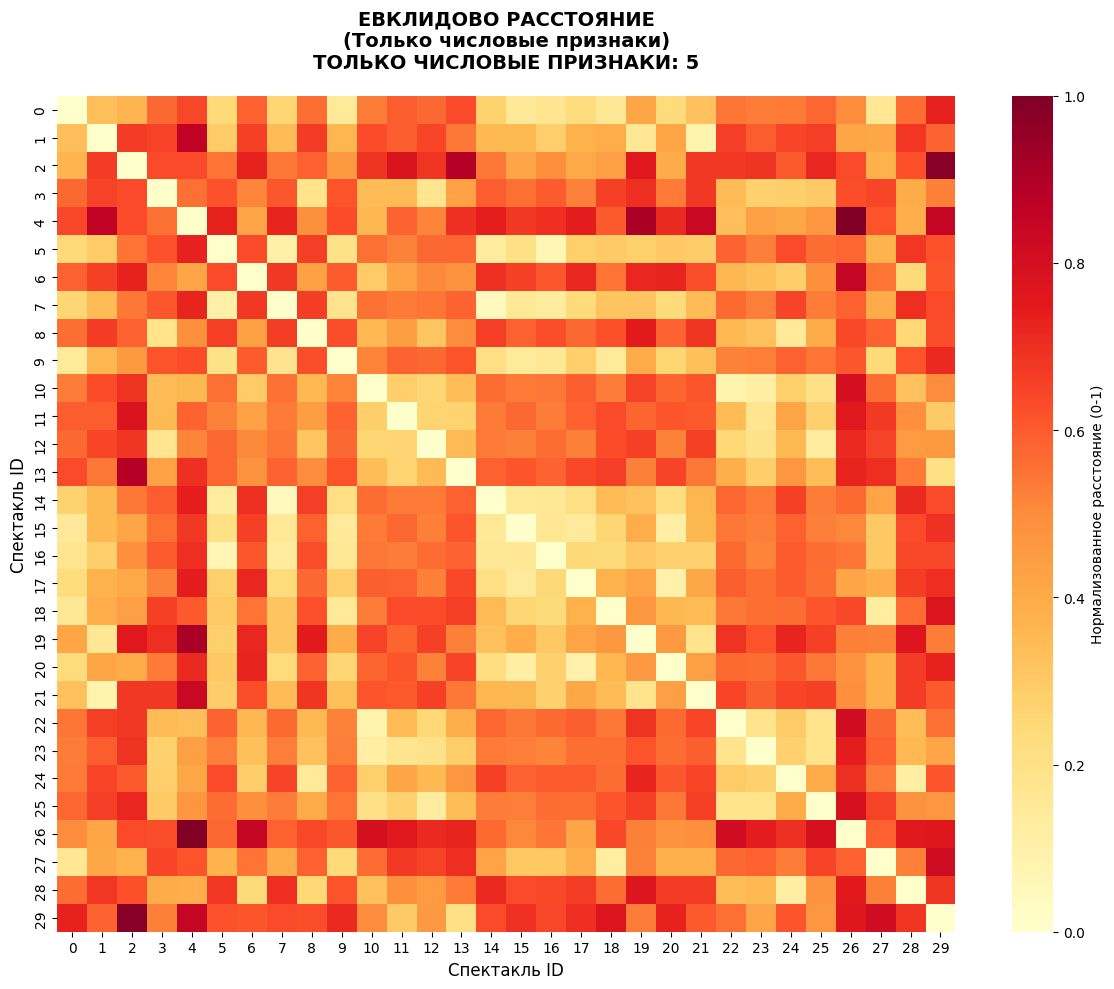


📊 ТЕПЛОВАЯ КАРТА 2: РАССТОЯНИЕ МАНХЭТТЕНА (ЧИСЛОВЫЕ ПРИЗНАКИ)


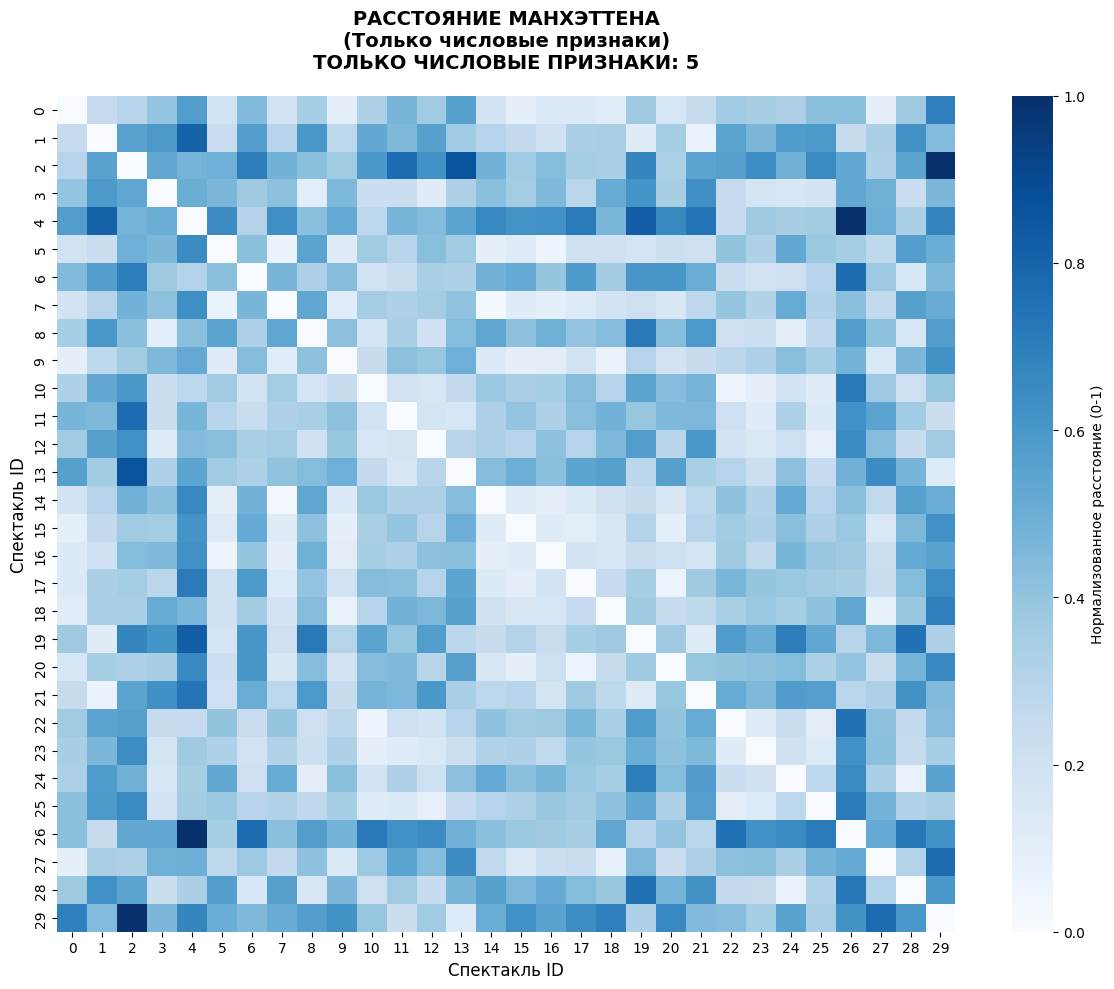


📊 ТЕПЛОВАЯ КАРТА 3: КОСИНУСНОЕ РАССТОЯНИЕ (ЧИСЛОВЫЕ ПРИЗНАКИ)


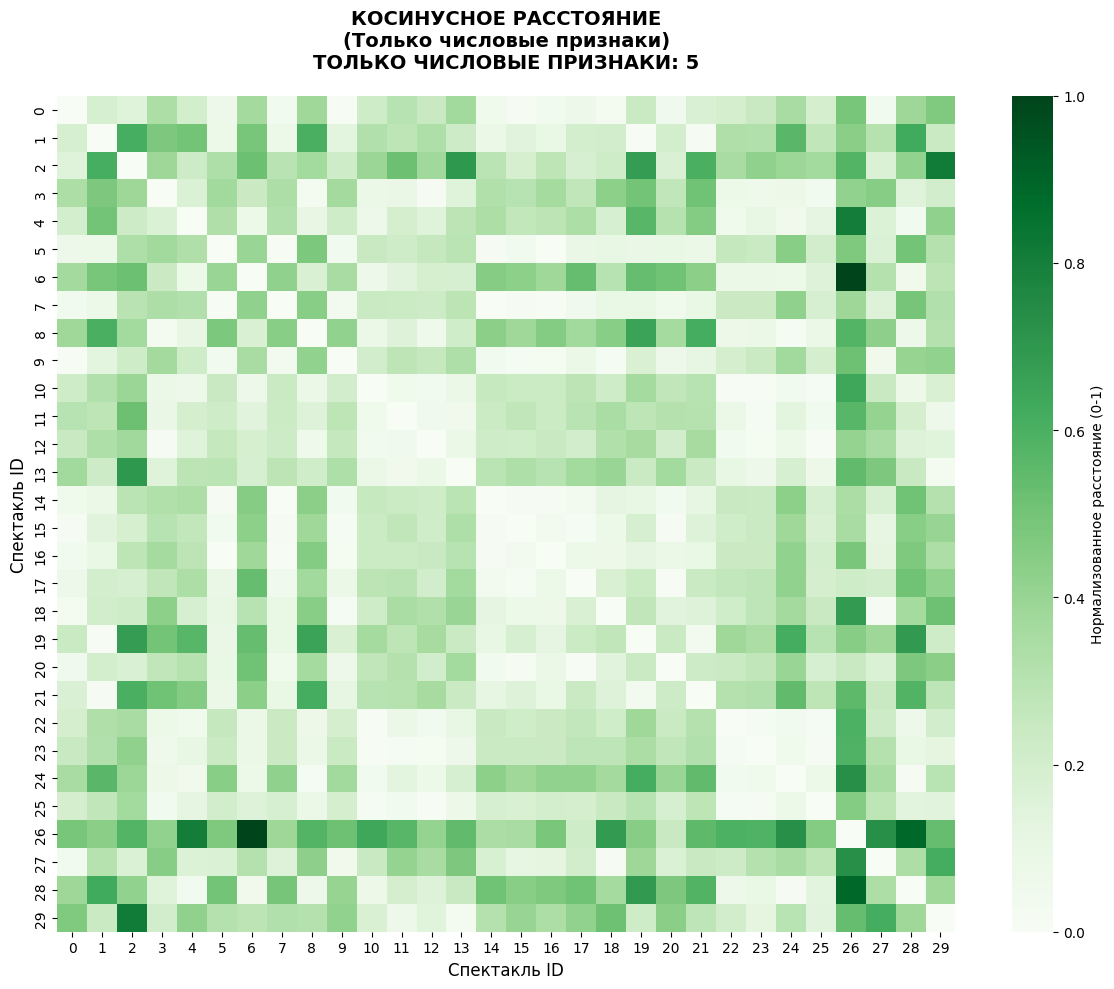


✅ Все тепловые карты для числовых признаков созданы!

📋 СРАВНИТЕЛЬНАЯ ТАБЛИЦА РАССТОЯНИЙ (ЧИСЛОВЫЕ ПРИЗНАКИ)
+----+------------------+-----------------+------------------+-----------+-------------------+-----------------------+-----------+
|    |  Тип расстояния  |   Мин. значение |   Макс. значение |   Среднее |   Стд. отклонение |   Уникальных значений |   Разброс |
+====+==================+=================+==================+===========+===================+=======================+===========+
|  0 |    EUCLIDEAN     |               0 |                1 |    0.4779 |            0.2014 |                   451 |         1 |
+----+------------------+-----------------+------------------+-----------+-------------------+-----------------------+-----------+
|  1 |    MANHATTAN     |               0 |                1 |    0.3661 |            0.1852 |                   432 |         1 |
+----+------------------+-----------------+------------------+-----------+-------------------+----------

'euclidean'

In [33]:
# Создаем экземпляр системы анализа числовых признаков
numeric_system = NumericDistanceAnalysisSystem(df)

# Запускаем полный анализ числовых признаков
numeric_system.run_numeric_analysis()